# 09 · Web 后端实战（员工管理）


来源：[飞书讲义《09-后端Web实战(员工管理)》](https://heuqqdmbyk.feishu.cn/wiki/PHp6wXaNUij3bokCXWrclz5anWh)。整理日期：2026-09-28。

正文依讲义顺序保留 571 个内容块、41 段原代码、61 张配图及 3 张嵌入表格；勘误与安全提示就近标注。原代码中同名类是逐步迭代的阶段性片段，不能全部一起放进项目。第 4 至 6 节补上员工新增与上传的请求链路、事务边界和跟练检查点。

图片以 Notebook 附件内嵌，可离线阅读。Java、XML、YAML 和 SQL 示例需放到对应项目或数据库工具中运行，Notebook 的 Python 内核不执行这些片段。课程推广内容未收录。


## 本章学习路线（补充）

第 08 章完成员工列表查询，本章处理新增。员工基本信息与工作经历落在两张表，因此先完成主键回填与批量插入，再用事务保证两表一致；头像由独立的上传接口处理，最后把返回地址交给新增员工请求。

| 阶段 | 核心问题 | 对应技术 |
| --- | --- | --- |
| 员工入库 | 怎样拿到新员工 ID？ | `POST /emps`、`@RequestBody`、MyBatis 主键回填 |
| 工作经历 | 如何一次写入多条？ | `EmpExprMapper`、XML `<foreach>` |
| 事务 | 第二次插入失败怎么办？ | `@Transactional`、回滚规则、传播行为 |
| 头像 | 上传后存在哪里？ | `MultipartFile`、本地存储、OSS |
| 配置 | 凭证和 Bucket 怎样配置？ | 环境变量、外部化配置、最小权限 |

本章不涉及员工修改、删除与后续登录认证接口。OSS 对象写入不属于数据库事务，必须单独考虑失败后的清理。


完成了员工管理的列表查询功能之后，接下来呢，我们再来完成新增员工的功能。 具体的需求如下：

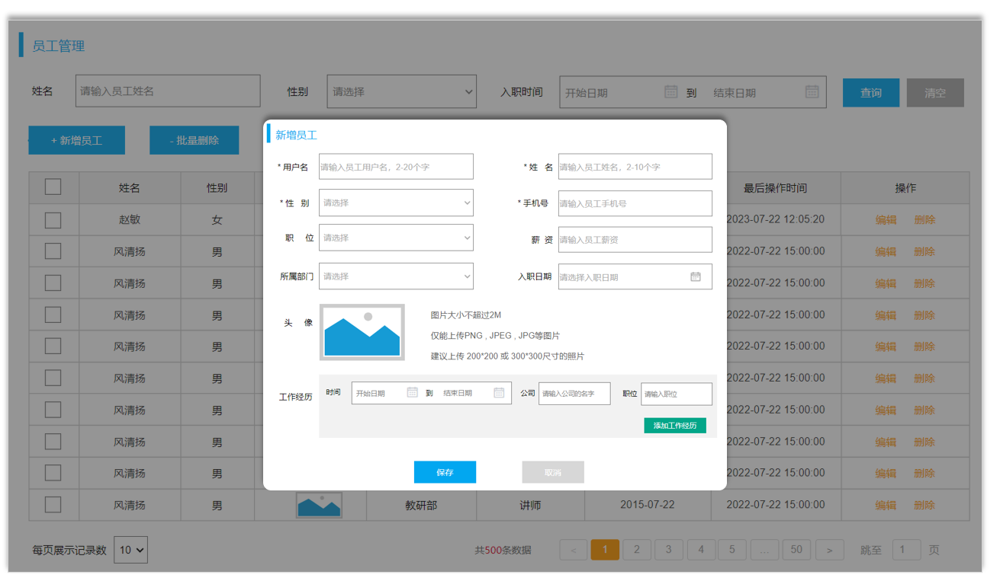

那么在新增员工的时候，涉及到两部分：新增员工、文件上传。 今天的课程内容包括如下几个部分：

- 新增员工
- 事务管理
- 文件上传


## 1 新增员工


### 1.1 需求

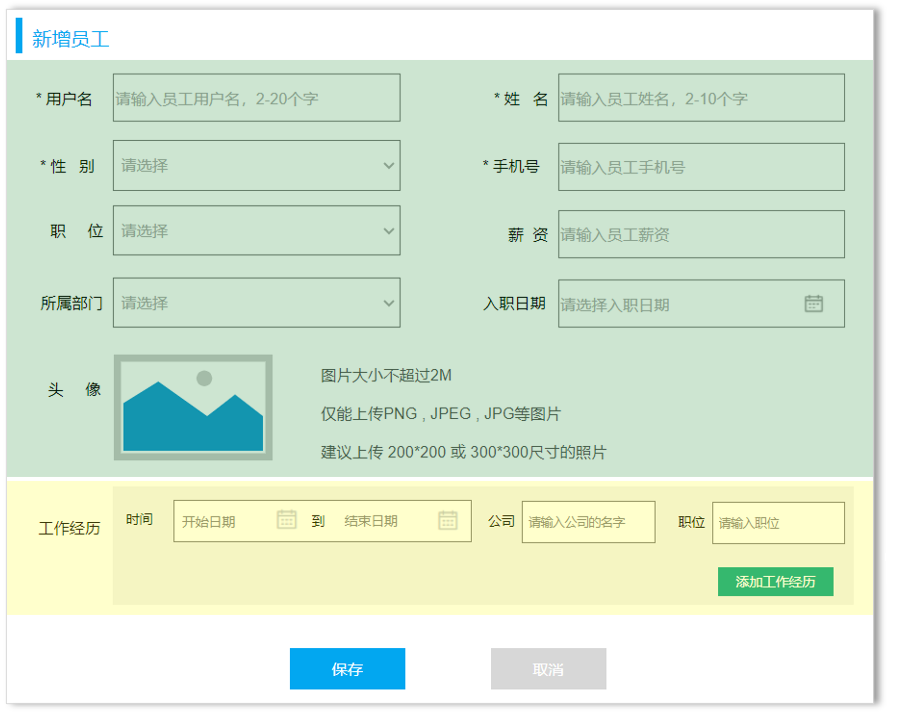

在新增员工的时候，在表单中，我们既要录入员工的基本信息，又要录入员工的工作经历信息。 员工基本信息，对应的表结构是 emp表，员工工作经历信息，对应的表结构是 emp&#95;expr 表，所以这里我们要操作两张表，往两张表中保存数据。


### 1.2 接口描述

参照提供的接口文档中 <code>员工管理</code> -&gt; <code>添加员工</code> 接口的描述。


### 1.3 思路分析

新增员工的具体的流程：

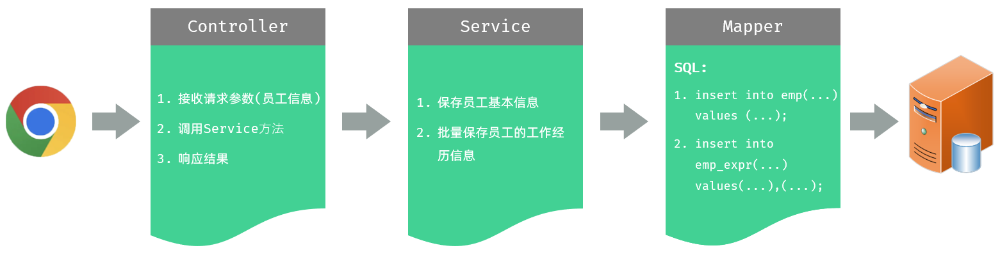

> - <strong>接口文档规定：</strong>
> 
>     - 请求路径：/emps
>     - 请求方式：POST
>     - 请求参数：Json格式数据
>     - 响应数据：Json格式数据
> - <strong>问题1：</strong>如何限定请求方式是POST？ <strong><code>@PostMapping</code></strong>
> - <strong>问题2：</strong>怎么在controller中接收json格式的请求参数？<strong><code>@RequestBody</code></strong>


### 1.4 功能开发


#### 1.4.1 准备工作

准备<code>EmpExprMapper</code>接口及映射配置文件<code>EmpExprMapper.xml</code>，并准备实体类接收前端传递的json格式的请求参数。

1). EmpExprMapper接口

````java
@Mapper
public interface EmpExprMapper {

}
````

2). EmpExprMapper.xml 配置文件

````xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpExprMapper">

</mapper>
````

> **MyBatis 参数提示：**`collection="exprList"` 要与 Mapper 参数名保持一致。为避免编译参数名配置变化造成绑定失败，可在 `insertBatch(@Param("exprList") List<EmpExpr> exprList)` 上显式命名。空列表应在 Service 层跳过批量插入，避免生成 `VALUES` 后无记录的 SQL。

3). 需要在 <code>Emp</code> 员工实体类中增加属性 <code>exprList</code> 来封装工作经历数据。 最终完整代码如下：

````java
@Data
public class Emp {
    private Integer id; //ID,主键
    private String username; //用户名
    private String password; //密码
    private String name; //姓名
    private Integer gender; //性别, 1:男, 2:女
    private String phone; //手机号
    private Integer job; //职位, 1:班主任,2:讲师,3:学工主管,4:教研主管,5:咨询师
    private Integer salary; //薪资
    private String image; //头像
    private LocalDate entryDate; //入职日期
    private Integer deptId; //关联的部门ID
    private LocalDateTime createTime; //创建时间
    private LocalDateTime updateTime; //修改时间

    //封装部门名称数
    private String deptName; //部门名称

    //封装员工工作经历信息
    private List<EmpExpr> exprList;
}
````


#### 1.4.2 保存员工基本信息

1). EmpController

在 <code>EmpController</code> 中增加save方法。

````java
/**
 * 添加员工
 */
@PostMapping
public Result save(@RequestBody Emp emp){
    log.info("请求参数emp: {}", emp);
    empService.save(emp);
    return Result.success();
}
````

> **安全提醒：**`Emp` 含 `password`、手机号等字段，不能把整个请求对象写入普通日志。真实项目宜用添加员工请求 DTO 接收入参，进行字段校验；密码由服务端按既定流程生成或设置，并只存储哈希。不要直接把数据库实体当作外部接口契约。

2). EmpService &amp; EmpServiceImpl

在 <code>EmpService</code> 中增加 save 方法

````java
/**
* 添加员工
* @param emp
*/
void save(Emp emp);
````

在 <code>EmpServiceImpl</code> 中增加save方法 , 实现接口中的save方法

````java
@Override
public void save(Emp emp) {
    //1.补全基础属性
    emp.setCreateTime(LocalDateTime.now());
    emp.setUpdateTime(LocalDateTime.now());
    
    //2.保存员工基本信息
    empMapper.insert(emp);

    //3. 保存员工的工作经历信息 - 批量 (稍后完成)
    
}
````

3). EmpMapper

在 <code>EmpMapper</code> 中增加insert方法，新增员工的基本信息。

````java
/**
* 新增员工数据
*/
@Options(useGeneratedKeys = true, keyProperty = "id")
@Insert("insert into emp(username, name, gender, phone, job, salary, image, entry_date, dept_id, create_time, update_time) " +
        "values (#{username},#{name},#{gender},#{phone},#{job},#{salary},#{image},#{entryDate},#{deptId},#{createTime},#{updateTime})")
void insert(Emp emp);
````

> **数据约束：**此 `INSERT` 没写 `password` 列，实际能否插入取决于数据库列的默认值和非空约束。不要依赖讲义练习库的弱默认密码；真实项目需要明确账号初始化策略，并对用户名唯一冲突作明确错误处理。`@Options` 回填主键依赖数据库生成主键，插入后才可使用 `emp.getId()`。

> <strong>主键返回</strong><strong>：</strong><code>@Options(useGeneratedKeys = true, keyProperty = "id")</code>
> 
> 由于稍后，我们在保存工作经历信息的时候，需要记录是哪位员工的工作经历。 所以，保存完员工信息之后，是需要获取到员工的ID的，那这里就需要通过Mybatis中提供的主键返回功能来获取。


#### 1.4.3 批量保存工作经历


##### 1.4.3.1 分析

一个员工，是可以有多段工作经历的，所以在页面上将来用户录入员工信息时，可以自己根据需要添加多段工作经历。页面原型展示如下：

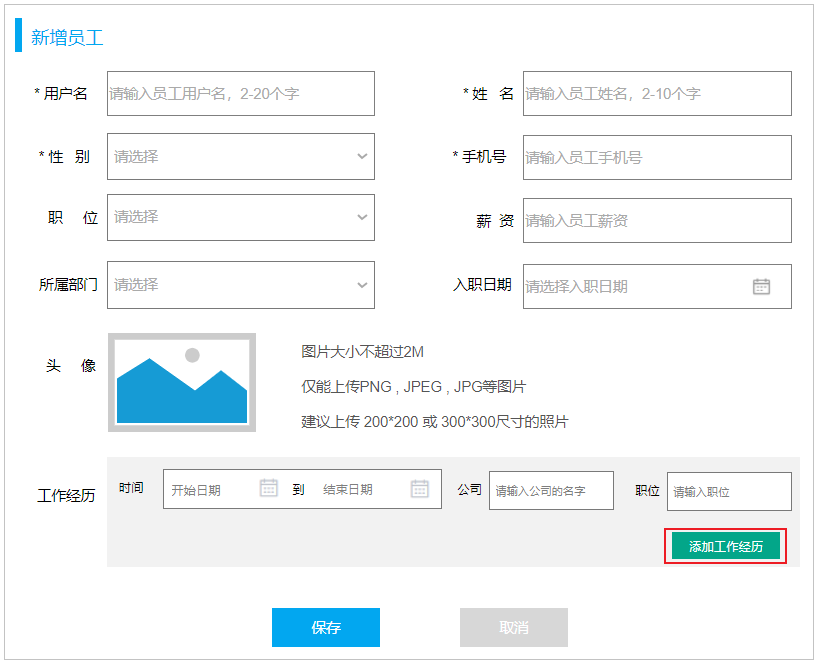

那如果员工只有一段工作经历，我们就需要往工作经历表中保存一条记录。 执行的SQL如下：

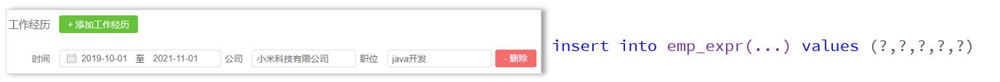

如果员工有两段工作经历，我们就需要往工作经历表中保存两条记录。执行的SQL如下：

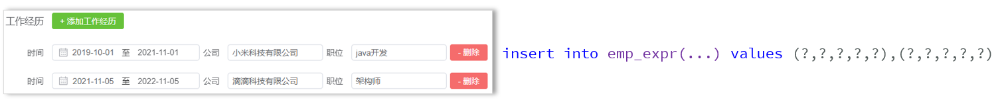

如果员工有三段工作经历，我们就需要往工作经历表中保存三条记录。执行的SQL如下：

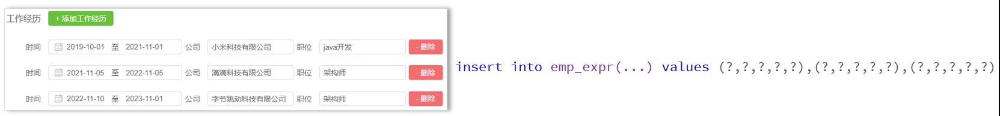

所以，这里最终我们需要执行的是批量插入数据的insert语句。


##### 1.4.3.2 实现

1). EmpServiceImpl

完善save方法中保存员工信息的逻辑。完整逻辑如下：

````java
@Override
public void save(Emp emp) {
    //1.补全基础属性
    emp.setCreateTime(LocalDateTime.now());
    emp.setUpdateTime(LocalDateTime.now());
    //2.保存员工基本信息
    empMapper.insert(emp);

    //3. 保存员工的工作经历信息 - 批量
    Integer empId = emp.getId();
    List<EmpExpr> exprList = emp.getExprList();
    if(!CollectionUtils.isEmpty(exprList)){
        exprList.forEach(empExpr -> empExpr.setEmpId(empId));
        empExprMapper.insertBatch(exprList);
    }
}
````

2). EmpExprMapper

````java
@Mapper
public interface EmpExprMapper {

    /**
     * 批量插入员工工作经历信息
     */
    public void insertBatch(List<EmpExpr> exprList);
}
````

3). EmpExprMapper.xml

````xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpExprMapper">

    <!--批量插入员工工作经历信息-->
    <insert id="insertBatch">
        insert into emp_expr (emp_id, begin, end, company, job) values
        <foreach collection="exprList" item="expr" separator=",">
            (#{expr.empId}, #{expr.begin}, #{expr.end}, #{expr.company}, #{expr.job})
        </foreach>
    </insert>

</mapper>
````

> 这里用到Mybatis中的动态SQL里提供的 <code>&lt;foreach&gt;</code> 标签，改标签的作用，是用来遍历循环，常见的属性说明：
> 
> 1. collection：集合名称
> 2. item：集合遍历出来的元素/项
> 3. separator：每一次遍历使用的分隔符
> 4. open：遍历开始前拼接的片段
> 5. close：遍历结束后拼接的片段
> 
> 上述的属性，是可选的，并不是所有的都是必须的。 可以自己根据实际需求，来指定对应的属性。


### 1.5 功能测试

代码开发完成后，重启服务器，打开 Apifox 发送 POST 请求，请求路径：http://localhost:8080/emps

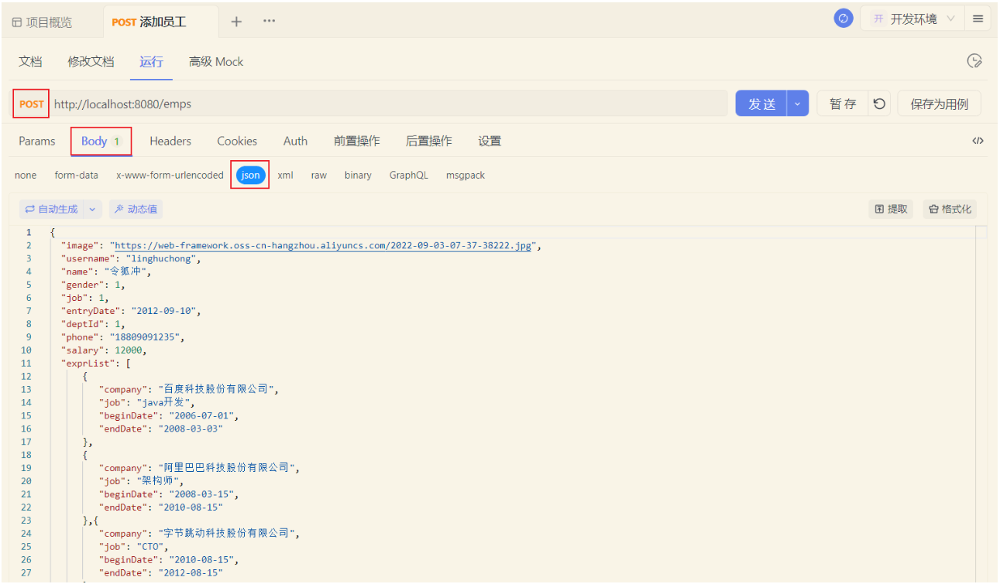

请求完毕后，可以打开idea的控制台看到控制台输出的日志：

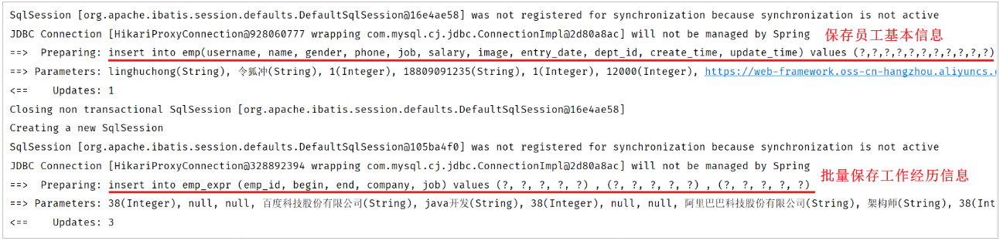


### 1.6 前后端联调

功能测试通过后，我们再进行通过打开浏览器，测试后端功能接口：

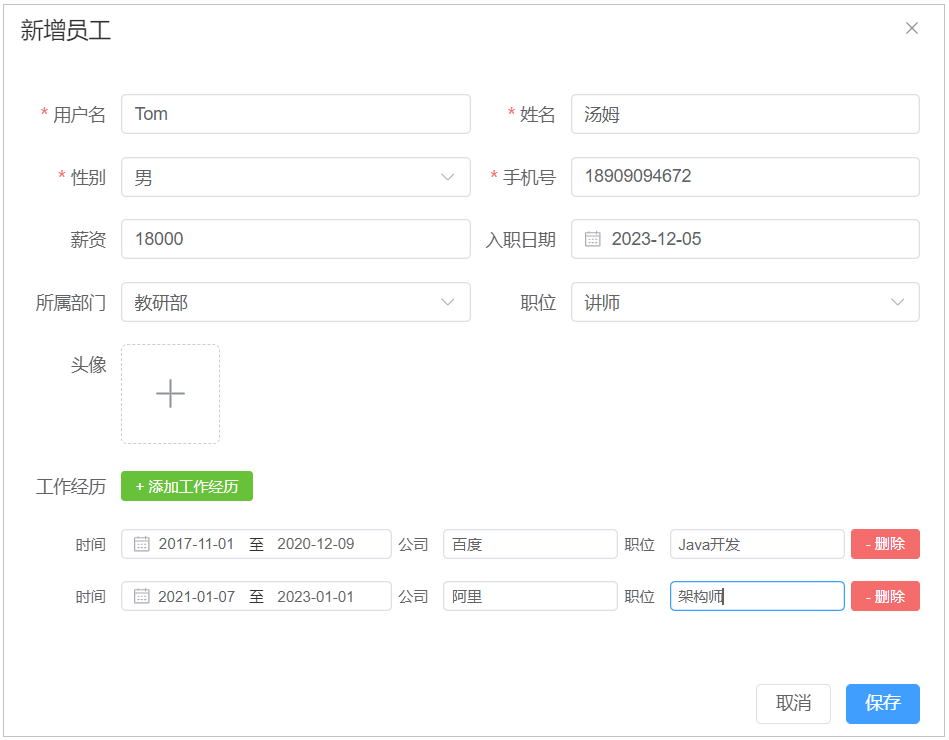

点击保存之后，可以看到列表中已经展示出了这条数据。


## 2 事务管理


### 2.1 问题分析

目前我们实现的新增员工功能中，操作了两次数据库，执行了两次 insert 操作。 

- 第一次：保存员工的基本信息到 <code>emp</code> 表中。
- 第二次：保存员工的工作经历信息到 <code>emp&#95;expr</code> 表中。

如果说，保存员工的基本信息成功了，而保存员工的工作经历信息出错了，会发生什么现象呢？那接下来，我们来做一个测试 。 我们可以在代码中，人为在保存员工的service层的save方法中，构造一个错误：

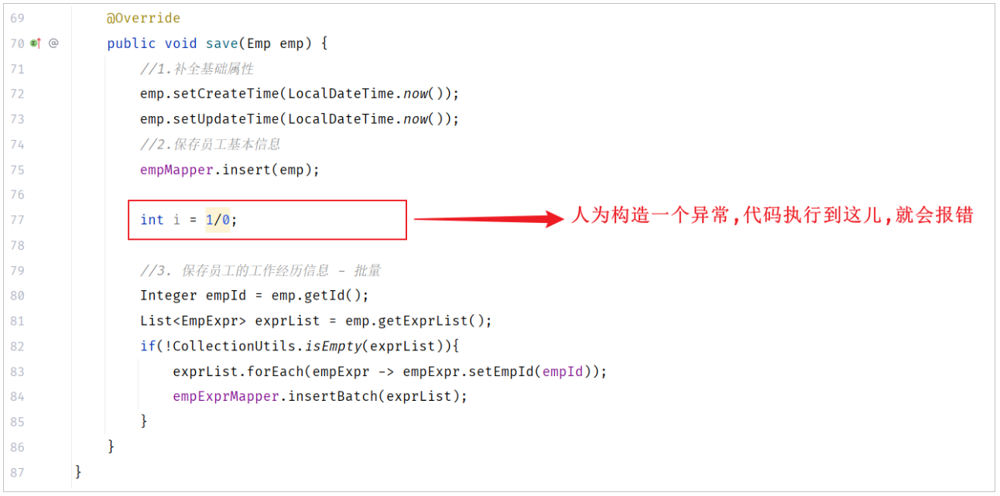

那接下来，我们就重启服务，打开浏览器，来做一个测试：

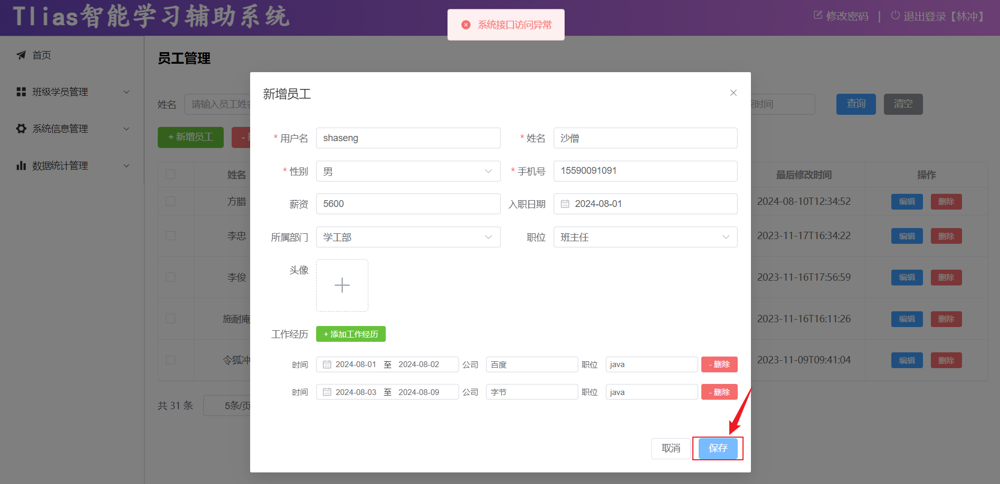

点击 “保存” 之后，提示 “系统接口异常”。我们可以打开IDEA控制台看一下，报出的错误信息。 我们看到，保存了员工的基本信息之后，系统出现了异常。

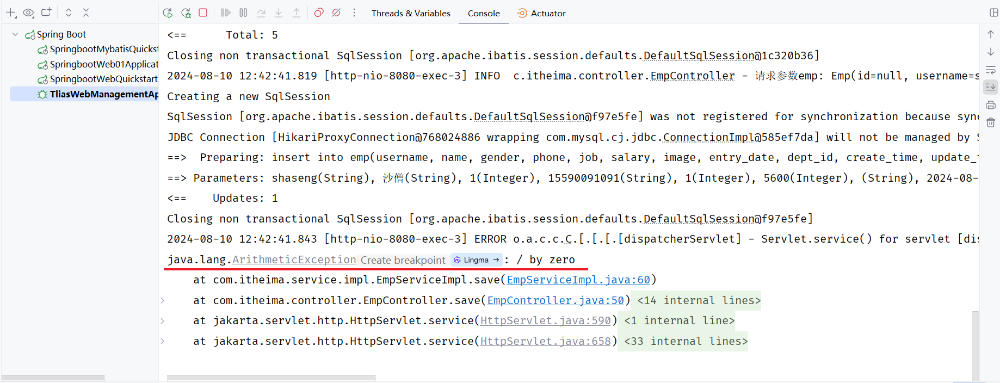

我们再打开数据库，看看表结构中的数据是否正常。

1). <code>emp</code> 员工表中是有 <code>shaseng</code> 这条数据的。

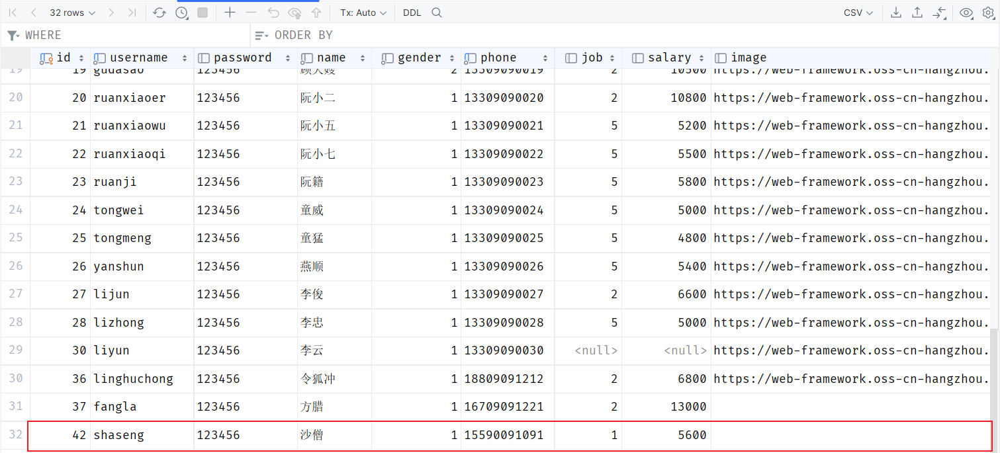

2). <code>emp&#95;expr</code> 表中没有该员工的工作经历信息。

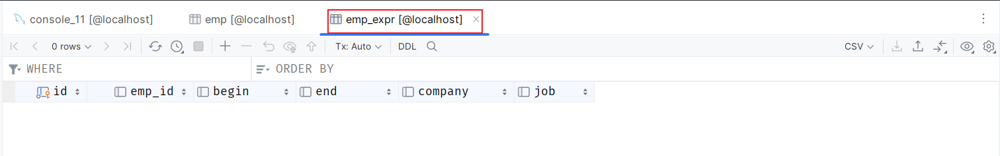

最终，我们看到，程序出现了异常 ，员工表 <code>emp</code> 数据保存成功了, 但是 <code>emp&#95;expr</code> 员工工作经历信息表，数据保存失败了。 那是否允许这种情况发生呢？

- 不允许
- 因为这属于一个业务操作，如果保存员工信息成功了，保存工作经历信息失败了，就会造成数据库数据的不完整、不一致。

那如何解决这个问题呢？ 这需要通过数据库中的<strong>事务</strong>来解决这个问题。


### 2.2 介绍

<strong>概念：</strong> 事务是一组操作的集合，它是一个不可分割的工作单位。事务会把所有的操作作为一个整体一起向系统提交或撤销操作请求，即这些操作 要么同时成功，要么同时失败。

就拿添加员工的这个业务为例，在这个业务操作中，包含了两个操作，那这两个操作是一个不可分割的工作单位。

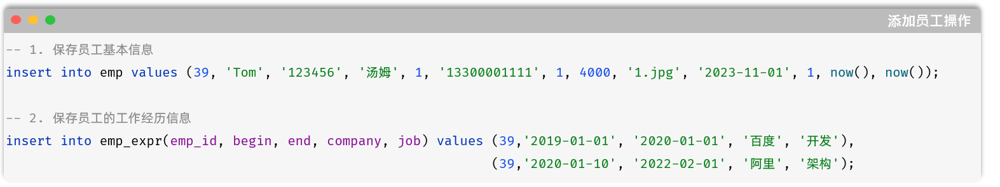

这两个操作，要么同时失败，要么同时成功。

> 默认MySQL的事务是自动提交的，也就是说，当执行一条DML语句，MySQL会立即隐式的提交事务。


### 2.3 操作

事务控制主要三步操作：开启事务、提交事务/回滚事务。

- 需要在这组操作执行之前，先开启事务  ( <code>start transaction; / begin;</code>)。
- 所有操作如果全部都执行成功，则提交事务 ( <code>commit;</code> )。
- 如果这组操作中，有任何一个操作执行失败，都应该回滚事务 ( <code>rollback</code> )。

那接下来，我们就可以将添加员工的业务操作，进行事务管理。 具体的SQL如下：

````sql
-- 开启事务
start transaction; / begin;

-- 1. 保存员工基本信息
insert into emp values (39, 'Tom', '123456', '汤姆', 1, '13300001111', 1, 4000, '1.jpg', '2023-11-01', 1, now(), now());

-- 2. 保存员工的工作经历信息
insert into emp_expr(emp_id, begin, end, company, job) values (39,'2019-01-01', '2020-01-01', '百度', '开发'),                                                                                                       (39,'2020-01-10', '2022-02-01', '阿里', '架构');

-- 提交事务(全部成功)
commit;

-- 回滚事务(有一个失败)
rollback;
````

> **SQL 勘误：**`start transaction; / begin;` 只是把两个可选写法并排说明，不能原样作为一条 SQL 执行。实际选 `START TRANSACTION;` 或 `BEGIN;` 之一；操作成功执行 `COMMIT;`，失败执行 `ROLLBACK;`，不能顺序执行两个结尾。示例中的明文密码仅供隔离练习库使用。

事务管理的场景，是非常多的，比如：

- 银行转账
- 下单扣减库存


### 2.4 Spring事务管理


#### 2.4.1 分析

在上述实现的新增员工的功能中，一旦在保存员工基本信息后出现异常。 我们就会发现，员工信息保存成功，但是工作经历信息保存失败，造成了数据的不完整不一致。

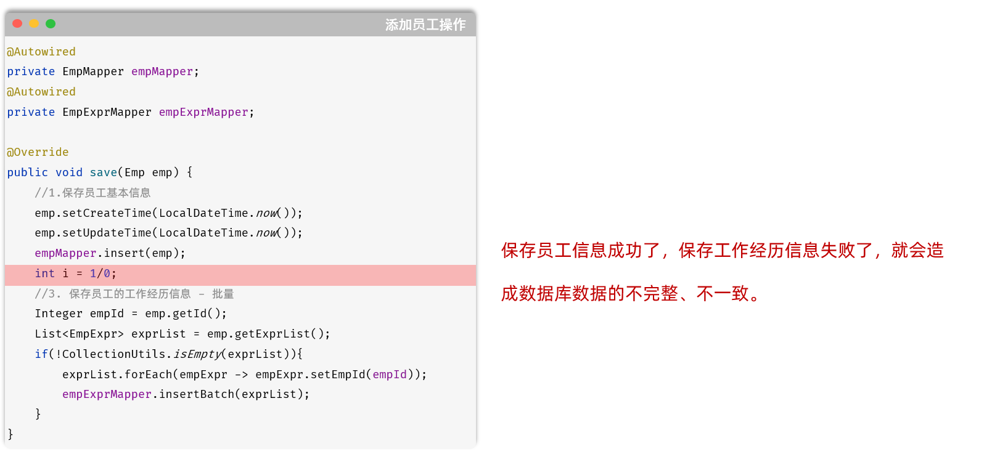

产生原因：

- 先执行新增员工的操作，这步执行完毕，就已经往员工表 <code>emp</code> 插入了数据。
- 执行 1/0 操作，抛出异常
- 抛出异常之前，下面所有的代码都不会执行了，批量保存工作经历信息，这个操作也不会执行 。

此时就出现问题了，员工基本信息保存了，员工的工作经历信息未保存，业务操作前后数据不一致。 

而要想保证操作前后，数据的一致性，就需要让新增员工中涉及到的两个业务操作，要么全部成功，要么全部失败 。 那我们如何，让这两个操作要么全部成功，要么全部失败呢 ？

那就可以通过事务来实现，因为一个事务中的多个业务操作，要么全部成功，要么全部失败。

此时，我们就需要在新增员工功能中添加事务。

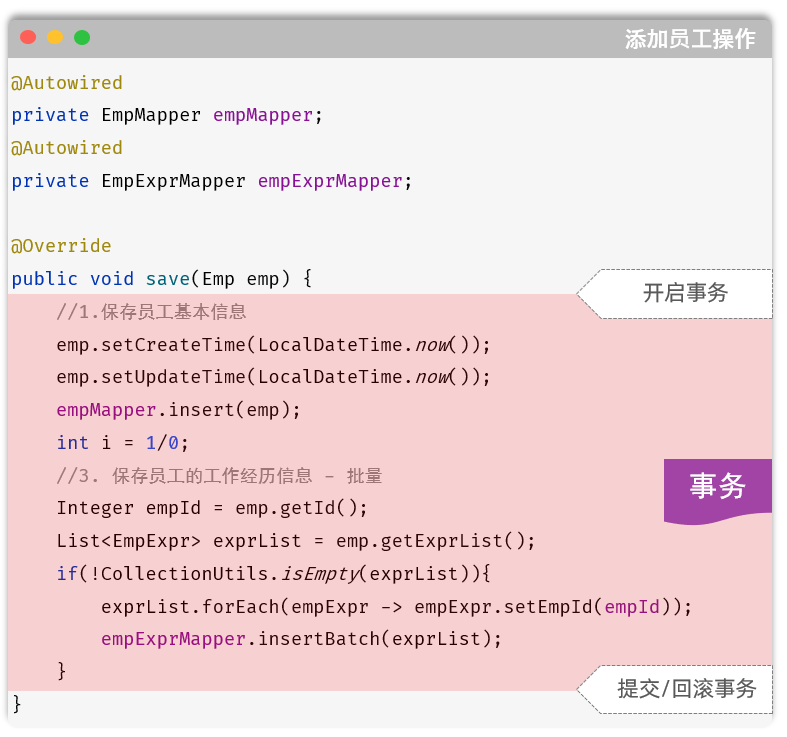

在方法运行之前，开启事务，如果方法成功执行，就提交事务，如果方法执行的过程当中出现异常了，就回滚事务。

<strong>思考：</strong>开发中所有的业务操作，一旦我们要进行控制事务，是不是都是这样的套路？

<strong>答案：</strong>是的。

所以在spring框架当中就已经把事务控制的代码都已经封装好了，并不需要我们手动实现。我们使用了spring框架，我们只需要通过一个简单的注解@Transactional就搞定了。


#### 2.4.2 Transactional注解

<strong>注解：</strong>@Transactional

<strong>作用：</strong>就是在当前这个方法执行开始之前来开启事务，方法执行完毕之后提交事务。如果在这个方法执行的过程当中出现了异常，就会进行事务的回滚操作。

<strong>位置：</strong>业务层的方法上、类上、接口上

- 方法上：当前方法交给spring进行事务管理
- 类上：当前类中所有的方法都交由spring进行事务管理 
- 接口上：接口下所有的实现类当中所有的方法都交给spring 进行事务管理

接下来，我们就可以在业务方法save上加上 <code>@Transactional</code> 来控制事务 。

````java
@Transactional
@Override
public void save(Emp emp) {
    //1.补全基础属性
    emp.setCreateTime(LocalDateTime.now());
    emp.setUpdateTime(LocalDateTime.now());
    //2.保存员工基本信息
    empMapper.insert(emp);

    int i = 1/0;

    //3. 保存员工的工作经历信息 - 批量
    Integer empId = emp.getId();
    List<EmpExpr> exprList = emp.getExprList();
    if(!CollectionUtils.isEmpty(exprList)){
        exprList.forEach(empExpr -> empExpr.setEmpId(empId));
        empExprMapper.insertBatch(exprList);
    }
}
````

@Transactional注解：我们一般会在业务层当中来控制事务，因为在业务层当中，一个业务功能可能会包含多个数据访问的操作。在业务层来控制事务，我们就可以将多个数据访问操作控制在一个事务范围内。

说明：可以在<code>application.yml</code>配置文件中开启事务管理日志，这样就可以在控制看到和事务相关的日志信息了

````yaml
#spring事务管理日志
logging: 
  level: 
    org.springframework.jdbc.support.JdbcTransactionManager: debug
````

接下来，我们再次添加员工，看看控制台输出的日志信息。

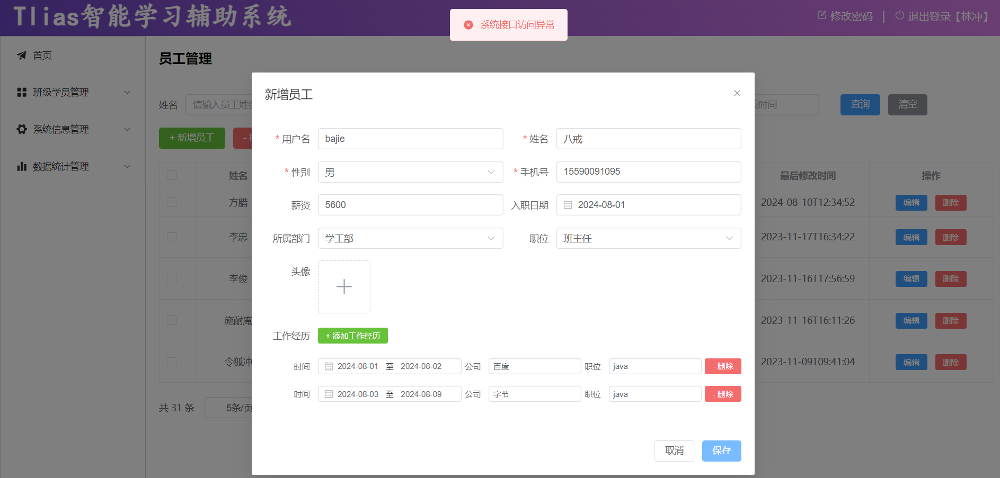

添加Spring事务管理后，由于服务端程序引发了异常，所以事务进行回滚。

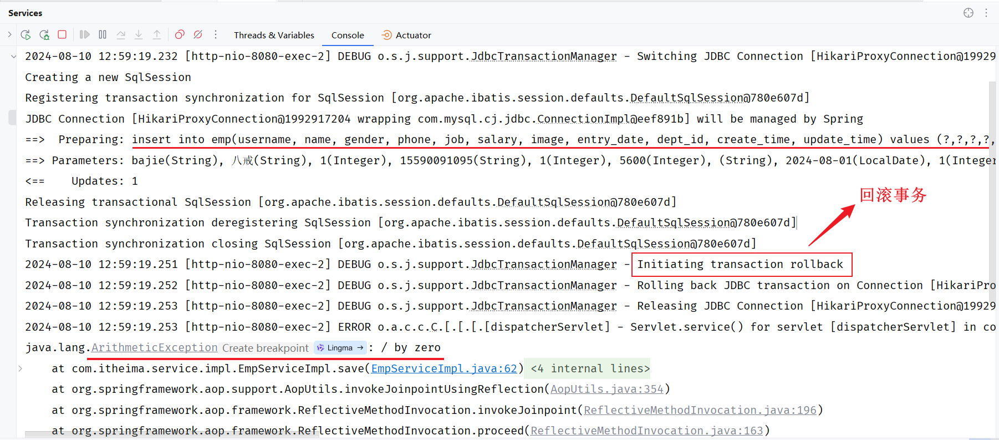

打开数据库，我们会看到 <code>emp</code> 表 与 <code>emp&#95;expr</code> 表中都没有对应的数据信息，保证了数据的一致性、完整性。


#### 2.4.3 事务进阶

前面我们通过spring事务管理注解@Transactional已经控制了业务层方法的事务。接下来我们要来详细的介绍一下@Transactional事务管理注解的使用细节。我们这里主要介绍@Transactional注解当中的两个常见的属性：

- 异常回滚的属性：<code>rollbackFor </code>
- 事务传播行为：<code>propagation</code>

我们先来学习下rollbackFor属性。


##### 2.4.3.1 rollbackFor

我们在之前编写的业务方法上添加了@Transactional注解，来实现事务管理。

````java
@Transactional
@Override
public void save(Emp emp) {
    //1.补全基础属性
    emp.setCreateTime(LocalDateTime.now());
    emp.setUpdateTime(LocalDateTime.now());
    //2.保存员工基本信息
    empMapper.insert(emp);
        
    int i = 1/0;
        
    //3. 保存员工的工作经历信息 - 批量
    Integer empId = emp.getId();
    List<EmpExpr> exprList = emp.getExprList();
    if(!CollectionUtils.isEmpty(exprList)){
        exprList.forEach(empExpr -> empExpr.setEmpId(empId));
        empExprMapper.insertBatch(exprList);
    }
}
````

以上业务功能save方法在运行时，会引发除0的算术运算异常(运行时异常)，出现异常之后，由于我们在方法上加了<code>@Transactional</code>注解进行事务管理，所以发生异常会执行rollback回滚操作，从而保证事务操作前后数据是一致的。

下面我们在做一个测试，我们修改业务功能代码，在模拟异常的位置上直接抛出Exception异常（编译时异常）

````java
@Transactional
@Override
public void save(Emp emp) {
    //1.补全基础属性
    emp.setCreateTime(LocalDateTime.now());
    emp.setUpdateTime(LocalDateTime.now());
    //2.保存员工基本信息
    empMapper.insert(emp);
        
    //模拟：异常发生
    if(true){
        throw new Exception("出现异常了~~~");
    }
        
    //3. 保存员工的工作经历信息 - 批量
    Integer empId = emp.getId();
    List<EmpExpr> exprList = emp.getExprList();
    if(!CollectionUtils.isEmpty(exprList)){
        exprList.forEach(empExpr -> empExpr.setEmpId(empId));
        empExprMapper.insertBatch(exprList);
    }
}
````

> **代码勘误：**此处的 `throw new Exception(...)` 是受检异常，而方法签名仍为 `save(Emp emp)`，直接复制无法编译；需在实现方法及接口上声明 `throws Exception`，或用一个真实会抛出受检异常的调用演示。默认回滚规则对 `RuntimeException` 和 `Error` 生效；受检异常须配置 `rollbackFor`。

> 说明：在service中向上抛出一个Exception编译时异常之后，由于是controller调用service，所以在controller中要有异常处理代码，此时我们选择在controller中继续把异常向上抛。

重新启动服务后，打开Apifox进行测试，请求添加员工的接口：

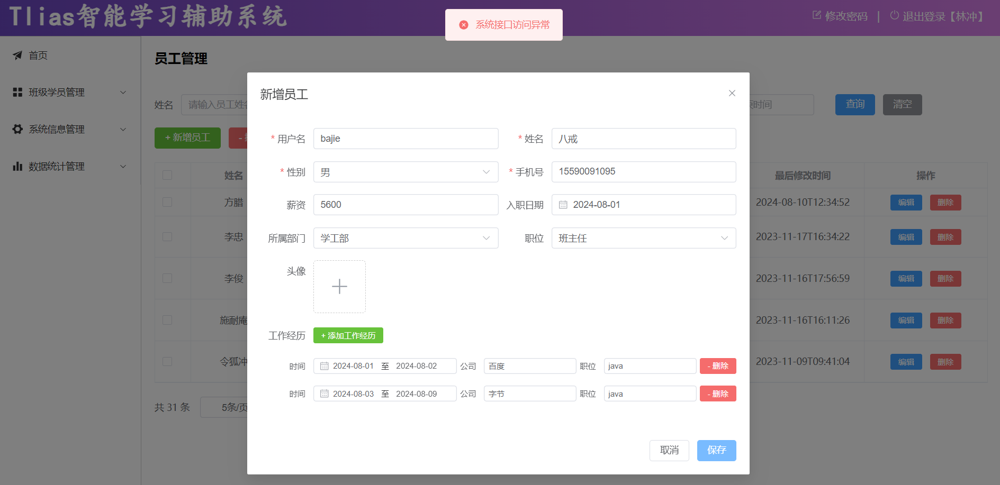

通过Apifox返回的结果，我们看到抛出异常了。然后我们在回到IDEA的控制台来看一下。

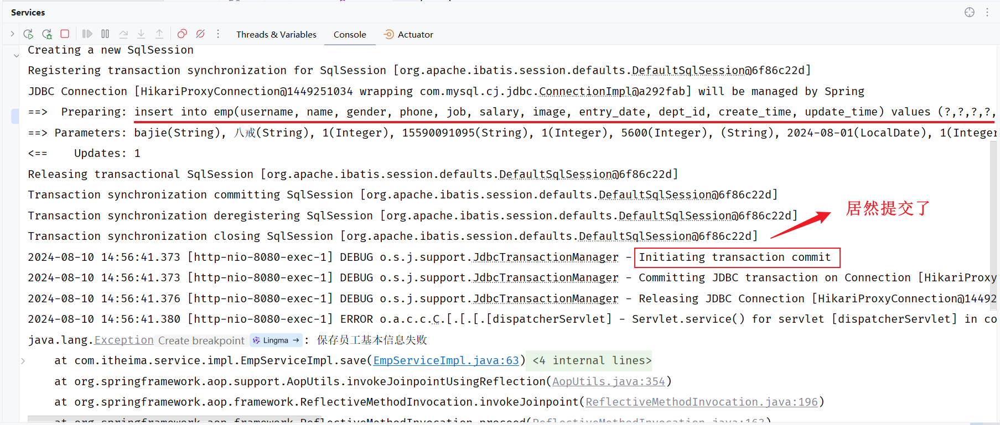

我们看到数据库的事务居然提交了，并没有进行回滚。

通过以上测试可以得出一个结论：<strong>默认情况下，只有出现RuntimeException(运行时异常)才会回滚事务。</strong>

假如我们想让所有的异常都回滚，需要来配置@Transactional注解当中的rollbackFor属性，通过rollbackFor这个属性可以指定出现何种异常类型回滚事务。

````java
@Transactional(rollbackFor = Exception.class)
@Override
public void save(Emp emp) throws Exception {
    //1.补全基础属性
    emp.setCreateTime(LocalDateTime.now());
    emp.setUpdateTime(LocalDateTime.now());
    //2.保存员工基本信息
    empMapper.insert(emp);
        
    //int i = 1/0;
    if(true){
        throw new Exception("出异常啦....");
    }
        
    //3. 保存员工的工作经历信息 - 批量
    Integer empId = emp.getId();
    List<EmpExpr> exprList = emp.getExprList();
    if(!CollectionUtils.isEmpty(exprList)){
        exprList.forEach(empExpr -> empExpr.setEmpId(empId));
        empExprMapper.insertBatch(exprList);
    }
}
````

> **事务边界：**`@Transactional(rollbackFor = Exception.class)` 应放在由 Spring 代理调用的公开 Service 方法上；同类内直接调用自身方法不会通过代理。异常被捕获后若未重新抛出或显式标记回滚，事务可能照常提交。这里的抛异常语句只用于演示，完成验证后应删去。

接下来我们重新启动服务，测试新增员工的操作：

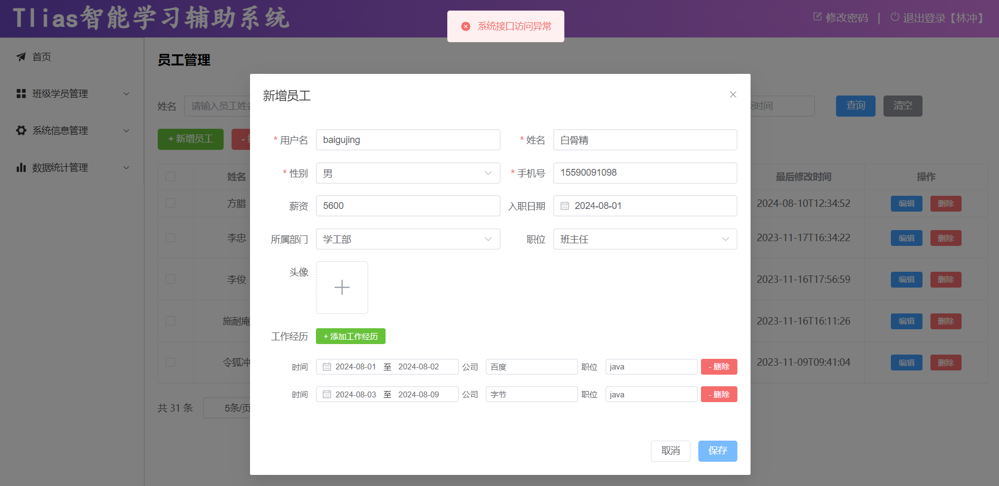

控制台日志，可以看到因为出现了异常又进行了事务回滚。

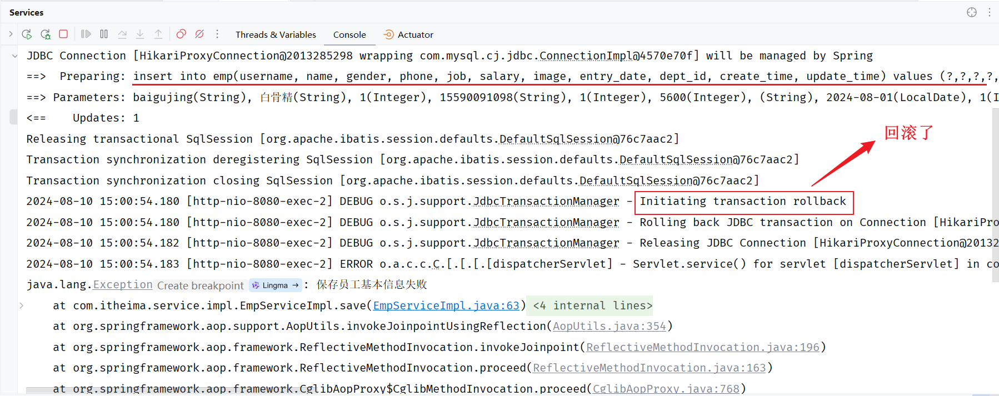

> <strong>结论：</strong>
> 
> - 在Spring的事务管理中，默认只有运行时异常 RuntimeException才会回滚。
> - 如果还需要回滚指定类型的异常，可以通过rollbackFor属性来指定。


##### 2.4.3.2 propagation


###### 2.4.3.2.1 介绍

我们接着继续学习@Transactional注解当中的第二个属性propagation，这个属性是用来配置事务的传播行为的。

什么是事务的传播行为呢？

- 就是当一个事务方法被另一个事务方法调用时，这个事务方法应该如何进行事务控制。

例如：两个事务方法，一个A方法，一个B方法。在这两个方法上都添加了@Transactional注解，就代表这两个方法都具有事务，而在A方法当中又去调用了B方法。

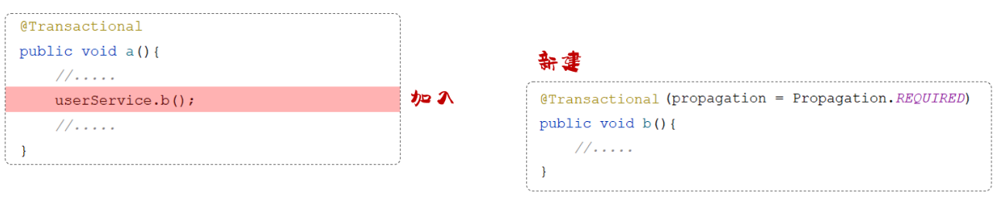

所谓事务的传播行为，指的就是在A方法运行的时候，首先会开启一个事务，在A方法当中又调用了B方法， B方法自身也具有事务，那么B方法在运行的时候，到底是加入到A方法的事务当中来，还是B方法在运行的时候新建一个事务？这个就涉及到了事务的传播行为。

我们要想控制事务的传播行为，在@Transactional注解的后面指定一个属性propagation，通过 propagation 属性来指定传播行为。接下来我们就来介绍一下常见的事务传播行为。

| 属性值 | 含义 |
| --- | --- |
| REQUIRED | 【默认值】需要事务，有则加入，无则创建新事务 |
| REQUIRES&#95;NEW | 需要新事务，无论有无，总是创建新事务 |
| SUPPORTS | 支持事务，有则加入，无则在无事务状态中运行 |
| NOT&#95;SUPPORTED | 不支持事务，在无事务状态下运行,如果当前存在已有事务,则挂起当前事务 |
| MANDATORY | 必须有事务，否则抛异常 |
| NEVER | 必须没事务，否则抛异常 |
| … |  |

> **传播行为速记：**`REQUIRED` 加入现有事务；`REQUIRES_NEW` 挂起外层事务并开启独立事务。内层提交后，外层回滚不会撤销内层；但内层失败若传播异常，仍可能使外层回滚。

> 对于这些事务传播行为，我们只需要关注以下两个就可以了：
> 
> 1. REQUIRED（默认值）
> 2. REQUIRES&#95;NEW


###### 2.4.3.2.2 案例

接下来我们就通过一个案例来演示下事务传播行为propagation属性的使用。

<strong>需求：</strong>在新增员工信息时，无论是成功还是失败，都要记录操作日志。

<strong>步骤：</strong>

1. 准备日志表 emp&#95;log、实体类EmpLog、Mapper接口EmpLogMapper
2. 在新增员工时记录日志

<strong>准备工作：</strong>

1). 创建数据库表 <code>emp&#95;log</code> 日志表

````sql
-- 创建员工日志表
create table emp_log(
    id int unsigned primary key auto_increment comment 'ID, 主键',
    operate_time datetime comment '操作时间',
    info varchar(2000) comment '日志信息'
) comment '员工日志表';
````

2). 引入资料中提供的实体类：EmpLog

````java
@Data
@NoArgsConstructor
@AllArgsConstructor
public class EmpLog {
    private Integer id; //ID
    private LocalDateTime operateTime; //操作时间
    private String info; //详细信息
}
````

3). 引入资料中提供的Mapper接口：EmpLogMapper

````java
@Mapper
public interface EmpLogMapper {
        //插入日志
    @Insert("insert into emp_log (operate_time, info) values (#{operateTime}, #{info})")
    public void insert(EmpLog empLog);
}
````

4). 引入资料中提供的业务接口：EmpLogService

````java
public interface EmpLogService {
        //记录新增员工日志
    public void insertLog(EmpLog empLog);
}
````

5). 引入资料中提供的业务实现类：EmpLogServiceImpl

````java
@Service
public class EmpLogServiceImpl implements EmpLogService {

    @Autowired
    private EmpLogMapper empLogMapper;

    @Transactional
    @Override
    public void insertLog(EmpLog empLog) {
        empLogMapper.insert(empLog);
    }
}
````

<strong>代码实现:</strong>

业务实现类：EmpServiceImpl

````java
@Autowired
private EmpMapper empMapper;
@Autowired
private EmpExprMapper empExprMapper;
@Autowired
private EmpLogService empLogService;

@Transactional(rollbackFor = {Exception.class})
@Override
public void save(Emp emp) {
    try {
        //1.补全基础属性
        emp.setCreateTime(LocalDateTime.now());
        emp.setUpdateTime(LocalDateTime.now());

        //2.保存员工基本信息
        empMapper.insert(emp);

        int i = 1/0;

        //3. 保存员工的工作经历信息 - 批量
        Integer empId = emp.getId();
        List<EmpExpr> exprList = emp.getExprList();
        if(!CollectionUtils.isEmpty(exprList)){
            exprList.forEach(empExpr -> empExpr.setEmpId(empId));
            empExprMapper.insertBatch(exprList);
        }
    } finally {
        //记录操作日志
        EmpLog empLog = new EmpLog(null, LocalDateTime.now(), emp.toString());
        empLogService.insertLog(empLog);
    }

}
````

> **日志安全与失败处理：**`emp.toString()` 可能包含密码、手机号等敏感信息，日志表应只记录必要的操作标识和脱敏结果。`finally` 中写日志若也失败，会覆盖原业务异常；真实业务要定义日志失败的处理策略。`REQUIRES_NEW` 仅保证内层数据库事务独立提交，不使日志自动具备跨系统可靠性。

<strong>测试:</strong>

重新启动SpringBoot服务，测试新增员工操作 。我们可以看到控制台中输出的日志：

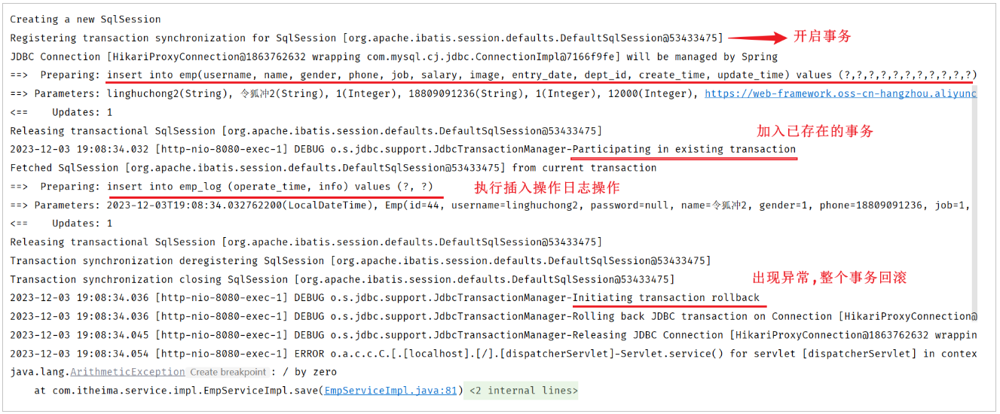

从日志中我们可以看到：

- 执行了插入员工数据的操作
- 执行了插入日志操作
- 程序发生Exception异常
- 执行事务回滚（保存员工数据、插入操作日志 因为在一个事务范围内，两个操作都会被回滚）

然后在 <code>emp&#95;log</code> 表中没有记录日志数据 。

<strong>原因分析</strong><strong>:</strong>

接下来我们就需要来分析一下具体是什么原因导致的日志没有成功的记录。

- 在执行 <code>save</code> 方法时开启了一个事务
- 当执行 <code>empLogService.insertLog</code> 操作时，<code>insertLog</code>设置的事务传播行是默认值REQUIRED，表示有事务就加入，没有则新建事务
- 此时：<code>save</code> 和 <code>insertLog</code> 操作使用了同一个事务，同一个事务中的多个操作，要么同时成功，要么同时失败，所以当异常发生时进行事务回滚，就会回滚 <code>save</code> 和  <code>insertLog</code> 操作

<strong>解决方案：</strong>

在<code>EmpLogServiceImpl</code>类中insertLog方法上，添加 <code>@Transactional(propagation = Propagation.REQUIRES&#95;NEW)</code>

> Propagation.REQUIRES&#95;NEW  ：不论是否有事务，都创建新事务  ，运行在一个独立的事务中。

````java
@Service
public class EmpLogServiceImpl implements EmpLogService {

    @Autowired
    private EmpLogMapper empLogMapper;

    @Transactional(propagation = Propagation.REQUIRES_NEW)
    @Override
    public void insertLog(EmpLog empLog) {
        empLogMapper.insert(empLog);
    }
}
````

重启SpringBoot服务，再次测试 新增员工的操作 ，会看到具体的日志如下：

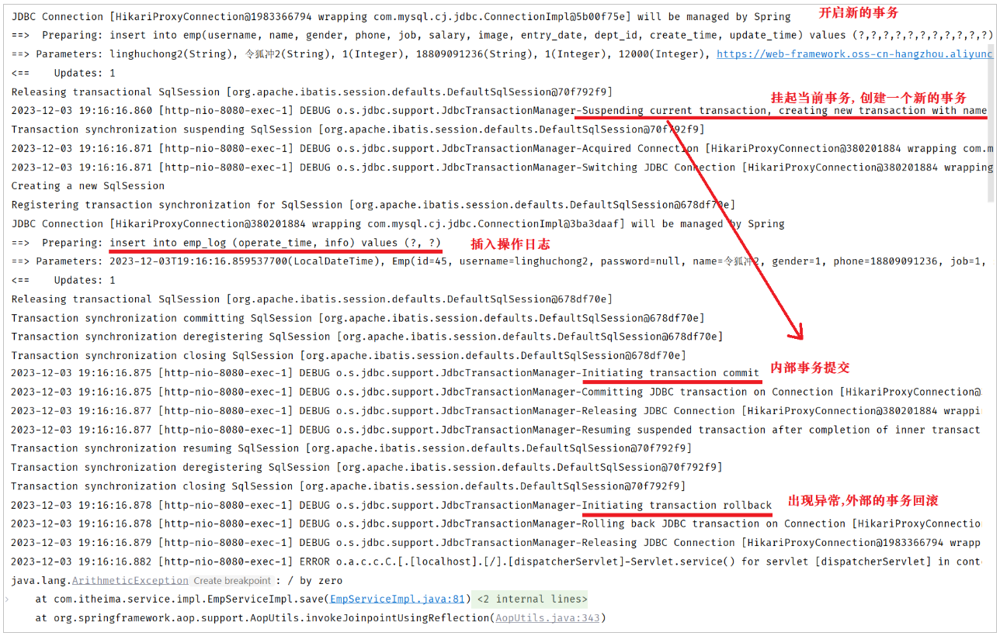

那此时，<code>EmpServiceImpl</code> 中的 <code>save</code> 方法运行时，会开启一个事务。 当调用  <code>empLogService.insertLog(empLog)</code>  时，也会创建一个新的事务，那此时，当 <code>insertLog</code> 方法运行完毕之后，事务就已经提交了。 即使外部的事务出现异常，内部已经提交的事务，也不会回滚了，因为是两个独立的事务。

到此事务传播行为已演示完成，事务的传播行为我们只需要掌握两个：REQUIRED、REQUIRES&#95;NEW。

> - <strong>REQUIRED：</strong>大部分情况下都是用该传播行为即可。
> - <strong>REQUIRES&#95;NEW：</strong>当我们不希望事务之间相互影响时，可以使用该传播行为。比如：下订单前需要记录日志，不论订单保存成功与否，都需要保证日志记录能够记录成功。


### 2.5 事务四大特性

面试题：事务有哪些特性？

- 原子性（Atomicity）：事务是不可分割的最小单元，要么全部成功，要么全部失败。
- 一致性（Consistency）：事务完成时，必须使所有的数据都保持一致状态。
- 隔离性（Isolation）：数据库系统提供的隔离机制，保证事务在不受外部并发操作影响的独立环境下运行。
- 持久性（Durability）：事务一旦提交或回滚，它对数据库中的数据的改变就是永久的。

> 事务的四大特性简称为：ACID

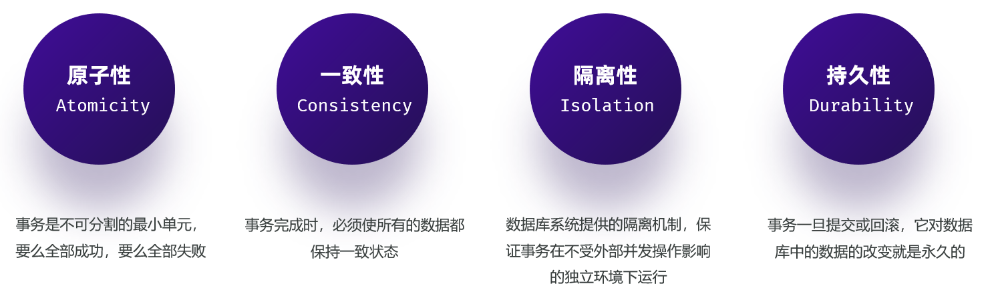

- <strong>原子性（Atomicity）</strong> ：原子性是指事务包装的一组sql是一个不可分割的工作单元，事务中的操作要么全部成功，要么全部失败。
- <strong>一致性（Consistency）</strong>：一个事务完成之后数据都必须处于一致性状态。

    - 如果事务成功的完成，那么数据库的所有变化将生效。
    - 如果事务执行出现错误，那么数据库的所有变化将会被回滚(撤销)，返回到原始状态。
- <strong>隔离性（Isolation）</strong>：多个用户并发的访问数据库时，一个用户的事务不能被其他用户的事务干扰，多个并发的事务之间要相互隔离。

    - 一个事务的成功或者失败对于其他的事务是没有影响。
- <strong>持久性（Durability）</strong>：一个事务一旦被提交或回滚，它对数据库的改变将是永久性的，哪怕数据库发生异常，重启之后数据亦然存在。


## 3 文件上传

在我们完成的 新增员工 功能中，还存在一个问题：没有头像(图片缺失)

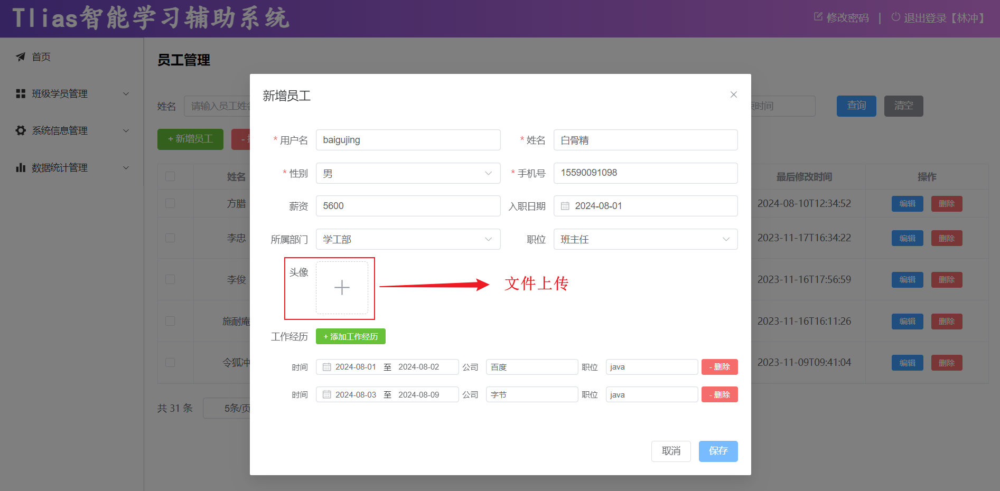

上述问题，需要我们通过<strong>文件上传</strong>技术来解决。下面我们就进入到文件上传技术的学习。

文件上传技术这块我们主要讲解三个方面：首先我们先对文件上传做一个整体的介绍，接着再学习文件上传的本地存储方式，最后学习云存储方式。

接下来我们就先来学习下什么是文件上传。


### 3.1 简介

文件上传，是指将本地图片、视频、音频等文件上传到服务器，供其他用户浏览或下载的过程。

文件上传在项目中应用非常广泛，我们经常发微博、发微信朋友圈都用到了文件上传功能。

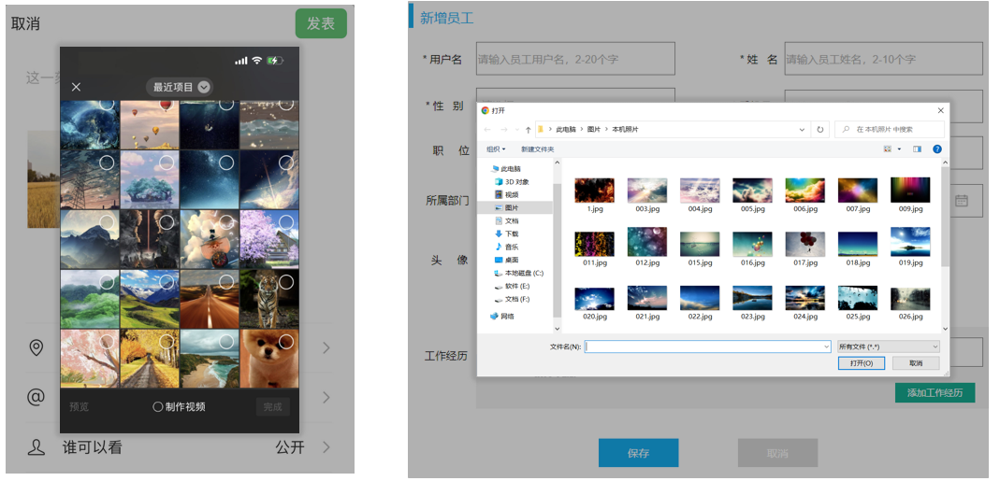

> 在我们的案例中，在新增员工的时候，要上传员工的头像，此时就会涉及到文件上传的功能。在进行文件上传时，我们点击加号或者是点击图片，就可以选择手机或者是电脑本地的图片文件了。当我们选择了某一个图片文件之后，这个文件就会上传到服务器，从而完成文件上传的操作。

> <strong>AI提示词：</strong>你是一名java开发工程师，现在正在学习文件上传功能，如何基于HTML+SpringBoot完成文件上传功能。

<strong>1). 生成的前端代码形式如下:</strong>

````html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>上传文件</title>
</head>
<body>

    <form action="/upload" method="post" enctype="multipart/form-data">
        姓名: <input type="text" name="username"><br>
        年龄: <input type="text" name="age"><br>
        头像: <input type="file" name="file"><br>
        <input type="submit" value="提交">
    </form>

</body>
</html>
````

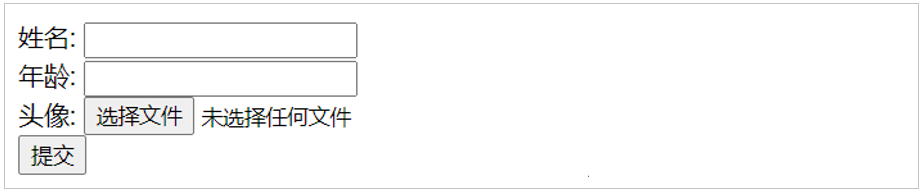

上传文件的原始form表单，要求表单必须具备以下三点（上传文件页面三要素）：

- 表单必须有file域，用于选择要上传的文件
- 表单提交方式必须为POST：通常上传的文件会比较大，所以需要使用 POST 提交方式
- 表单的编码类型enctype必须要设置为：multipart/form-data：普通默认的编码格式是不适合传输大型的二进制数据的，所以在文件上传时，表单的编码格式必须设置为multipart/form-data

前端页面的3要素我们了解后，接下来我们就来验证下所讲解的文件上传3要素。

在提供的"课程资料"中有一个名叫"文件上传"的文件夹，直接将里的 <code>upload.html</code> 文件，复制到springboot项目工程下的static目录里面。

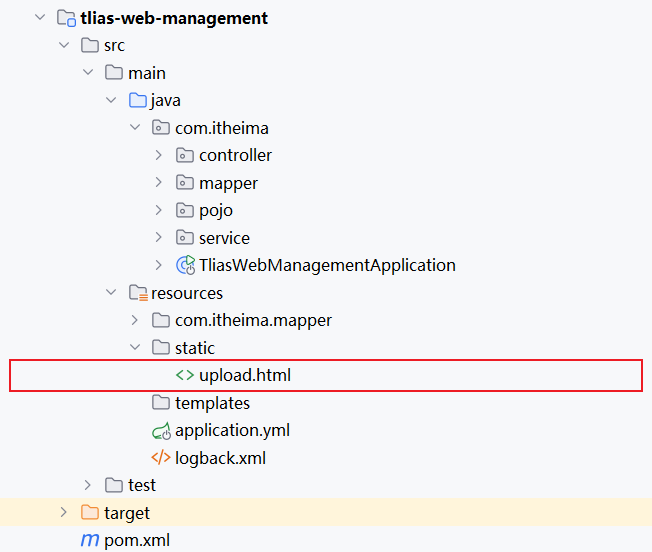

<strong>2). 生成的服务端代码形式如下</strong>

````java
package com.itheima.controller;

import lombok.extern.slf4j.Slf4j;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RestController;
import org.springframework.web.multipart.MultipartFile;

import java.io.File;
import java.io.IOException;

@Slf4j
@RestController
public class UploadController {

    /**
     * 上传文件 - 参数名file
     */
    @PostMapping("/upload")
    public Result upload(String username, Integer age , MultipartFile file) throws Exception {
        log.info("上传文件：{}, {}, {}", username, age, file);
        if(!file.isEmpty()){
            file.transferTo(new File("D:\\images\\" + file.getOriginalFilename()));
        }
        return Result.success();
    }

}
````

> **本地上传安全：**直接拼接 `getOriginalFilename()` 会有重名覆盖和路径穿越风险。即使只在本地练习，也应由服务端生成文件名、限定存储目录、校验扩展名与文件实际类型，并限制大小。原文件名只作不可信的展示数据。

在定义的方法中接收提交过来的数据 （方法中的形参名和请求参数的名字保持一致）

- 用户名：<code>String  name</code>
- 年龄： <code>Integer  age</code>
- 文件： <code>MultipartFile  file</code>

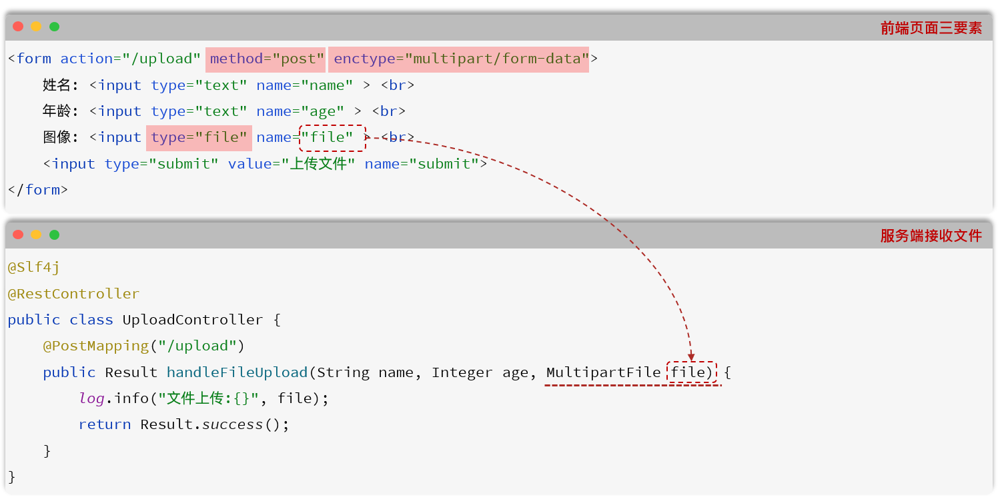

> Spring中提供了一个API：MultipartFile，使用这个API就可以来接收到上传的文件

<strong>问题1：如果表单项的名字和方法中形参名不一致，该怎么办？</strong>

````java
public Result upload(String username, 
                        Integer age,  
                        MultipartFile image) //image形参名和请求参数名file不一致
````

<strong>解决：使用@RequestParam注解进行参数绑定</strong>

````java
public Result upload(String username,
                     Integer age, 
                     @RequestParam("file") MultipartFile image)
````


### 3.2 本地存储

上面我们已经完成了文件上传最基本的功能实现，已经可以在服务端接收到上传的文件，并将文件保存在本地服务器的磁盘目录中了。 但是我们测试的时候发现，如果上传的文件名相同，后面上传的会覆盖前面上传的文件，那接下来，我们就要来优化这一块的功能。

> <strong>AI提示词：</strong>请完善上述代码, 将接收到的文件存储在本地的磁盘目录中(D:/images)中, 并要保证上传的文件名不重复

<strong>代码实现如下：</strong>

````java
package com.itheima.controller;

import com.itheima.pojo.Result;
import lombok.extern.slf4j.Slf4j;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RestController;
import org.springframework.web.multipart.MultipartFile;
import java.io.File;
import java.util.UUID;

@Slf4j
@RestController
public class UploadController {

    private static final String UPLOAD_DIR = "D:/images/";
    /**
     * 上传文件 - 参数名file
     */
    @PostMapping("/upload")
    public Result upload(MultipartFile file) throws Exception {
        log.info("上传文件：{}, {}, {}", username, age, file);
        if (!file.isEmpty()) {
            // 生成唯一文件名
            String originalFilename = file.getOriginalFilename();
            String extName = originalFilename.substring(originalFilename.lastIndexOf("."));
            String uniqueFileName = UUID.randomUUID().toString().replace("-", "") + extName;
            // 拼接完整的文件路径
            File targetFile = new File(UPLOAD_DIR + uniqueFileName);

            // 如果目标目录不存在，则创建它
            if (!targetFile.getParentFile().exists()) {
                targetFile.getParentFile().mkdirs();
            }
            // 保存文件
            file.transferTo(targetFile);
        }
        return Result.success();
    }
}
````

> **代码勘误：**这一版 `upload(MultipartFile file)` 的日志仍引用 `username`、`age`，两变量未定义，复制后无法编译。删除多余占位参数，或让方法声明并接收这两个表单字段。另外，`lastIndexOf(".")` 在无扩展名时得到 `-1`，不能直接 `substring(-1)`；必须先检查文件名和允许的类型。目录创建失败也应明确报错。

> > <strong>MultipartFile 常见方法： </strong>
> > 
> > - <code>String  getOriginalFilename();</code>  //获取原始文件名
> > - <code>void  transferTo(File dest);</code><code> </code>   //将接收的文件转存到磁盘文件中
> > - <code>long  getSize();</code>   //获取文件的大小，单位：字节
> > - <code>byte&#91;&#93;  getBytes();</code><code> </code>   //获取文件内容的字节数组
> > - <code>InputStream  getInputStream();</code>    //获取接收到的文件内容的输入流

利用 <code>Apifox</code> 测试，注意：请求参数名和controller方法形参名保持一致。

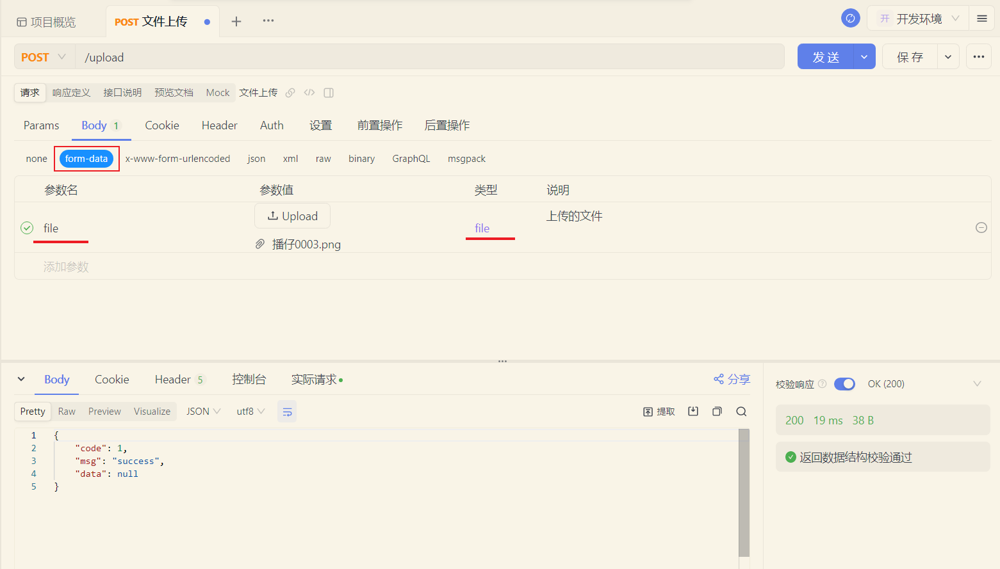

通过 <code>Apifox</code> 测试，我们发现文件上传是没有问题的。

在解决了文件名唯一性的问题后，我们再次上传一个较大的文件(超出1M)时发现，后端程序报错：

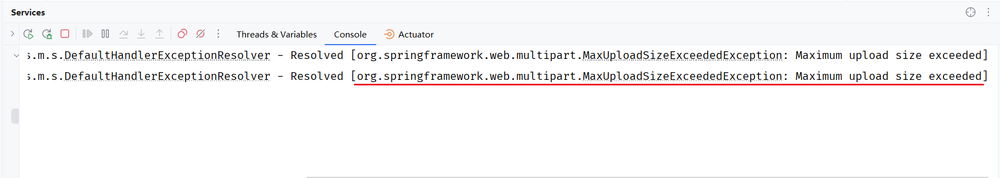

报错原因呢，是因为：在SpringBoot中，文件上传时默认单个文件最大大小为1M

那么如果需要上传大文件，可以在 <code>application.properties</code> 进行如下配置：

````yaml
spring：
  servlet:
    multipart:
      max-file-size: 10MB
      max-request-size: 100MB
````

> **YAML 勘误：**`spring：` 使用了全角冒号，配置不会按 `spring.servlet.multipart` 生效；应写半角 `spring:`。课程示例限制单文件 10 MB、单请求 100 MB，应按头像业务再缩小并在网关和应用两层统一限制。配置只能提高大小上限，不能代替类型与内容校验。

到时此，我们文件上传的本地存储方式已完成了。但是这种本地存储方式还存在一问题： 

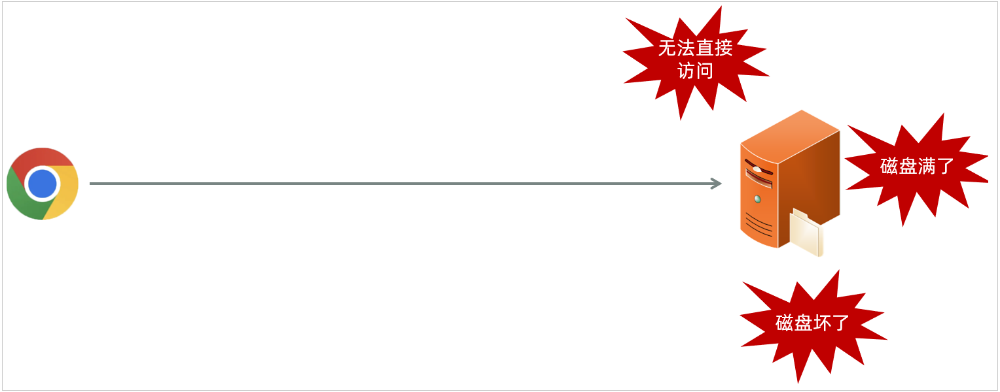

如果直接存储在服务器的磁盘目录中，存在以下缺点：

- 不安全：磁盘如果损坏，所有的文件就会丢失
- 容量有限：如果存储大量的图片，磁盘空间有限(磁盘不可能无限制扩容)
- 无法直接访问

为了解决上述问题呢，通常有两种解决方案：

- 自己搭建存储服务器，如：fastDFS 、MinIO
- 使用现成的云服务，如：阿里云，腾讯云，华为云


### 3.3 阿里云OSS


#### 3.3.1 准备


##### 3.3.1.1 介绍

阿里云是阿里巴巴集团旗下全球领先的云计算公司，也是国内最大的云服务提供商 。

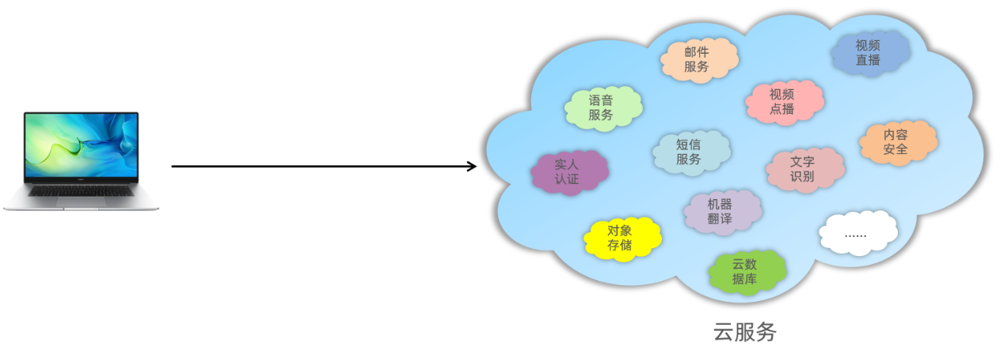

> <strong>云服务</strong>指的就是通过互联网对外提供的各种各样的服务，比如像：语音服务、短信服务、邮件服务、视频直播服务、文字识别服务、对象存储服务等等。
> 
> 当我们在项目开发时需要用到某个或某些服务，就不需要自己来开发了，可以直接使用阿里云提供好的这些现成服务就可以了。比如：在项目开发当中，我们要实现一个短信发送的功能，如果我们项目组自己实现，将会非常繁琐，因为你需要和各个运营商进行对接。而此时阿里云完成了和三大运营商对接，并对外提供了一个短信服务。我们项目组只需要调用阿里云提供的短信服务，就可以很方便的来发送短信了。这样就降低了我们项目的开发难度，同时也提高了项目的开发效率。（大白话：别人帮我们实现好了功能，我们只要调用即可）
> 
> 云服务提供商给我们提供的软件服务通常是需要收取一部分费用的。

阿里云对象存储OSS（Object Storage Service），是一款海量、安全、低成本、高可靠的云存储服务。使用OSS，您可以通过网络随时存储和调用包括文本、图片、音频和视频等在内的各种文件。

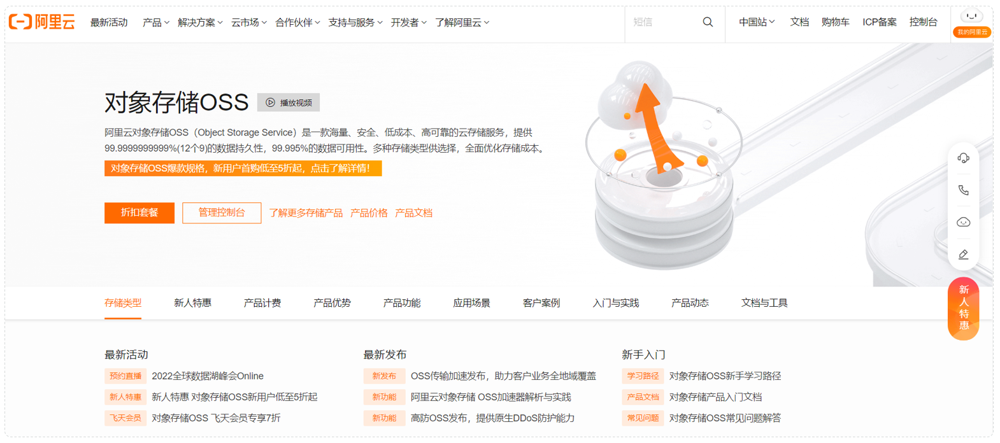

在我们使用了阿里云OSS对象存储服务之后，我们的项目当中如果涉及到文件上传这样的业务，在前端进行文件上传并请求到服务端时，在服务器本地磁盘当中就不需要再来存储文件了。我们直接将接收到的文件上传到oss，由 oss帮我们存储和管理，同时阿里云的oss存储服务还保障了我们所存储内容的安全可靠。

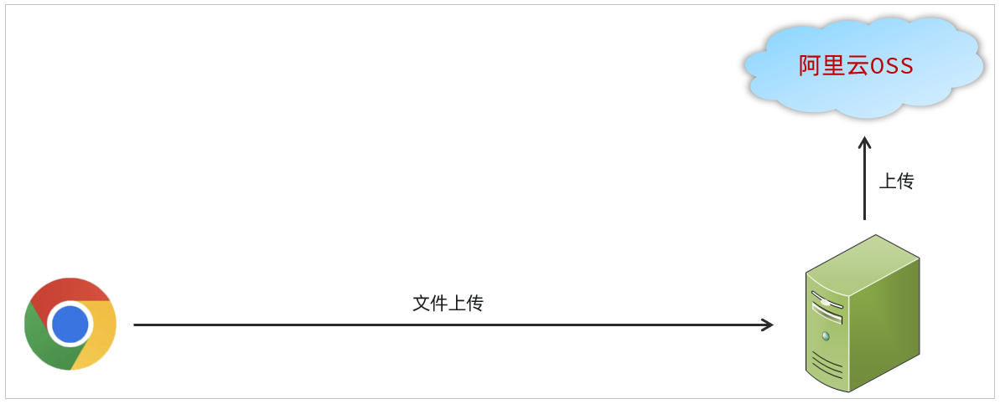

那我们学习使用这类云服务，我们主要学习什么呢？其实我们主要学习的是如何在项目当中来使用云服务完成具体的业务功能。而无论使用什么样的云服务，阿里云也好，腾讯云、华为云也罢，在使用第三方的服务时，操作的思路都是一样的。

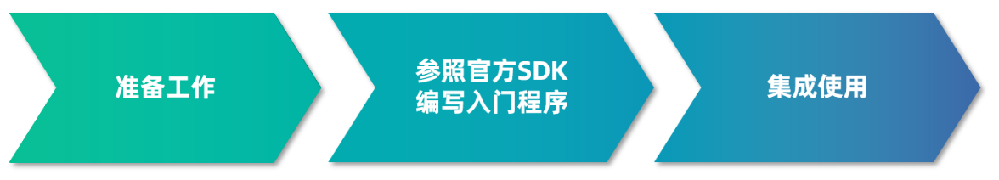

> <strong>SDK</strong><strong>：</strong>Software Development Kit 的缩写，软件开发工具包，包括辅助软件开发的依赖（jar包）、代码示例等，都可以叫做SDK。
> 
> 简单说，sdk中包含了我们使用第三方云服务时所需要的依赖，以及一些示例代码。我们可以参照sdk所提供的示例代码就可以完成入门程序。

第三方服务使用的通用思路，我们做一个简单介绍之后，接下来我们就来介绍一下我们当前要使用的阿里云oss对象存储服务具体的使用步骤。

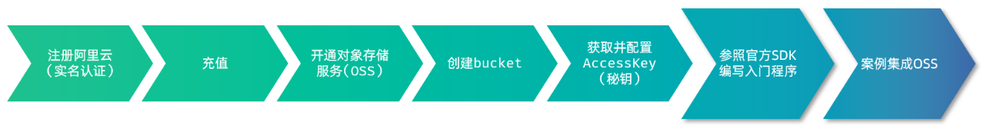

> <strong>Bucket：</strong>存储空间是用户用于存储对象（Object，就是文件）的容器，所有的对象都必须隶属于某个存储空间。


##### 3.3.1.2 账号准备

下面我们根据之前介绍的使用步骤，完成准备工作：

<strong>1). 注册阿里云账户（注册完成后需要实名认证）</strong>

https://account.aliyun.com/login/login.htm?oauth&#95;callback=https%3A%2F%2Fwww.aliyun.com%2F

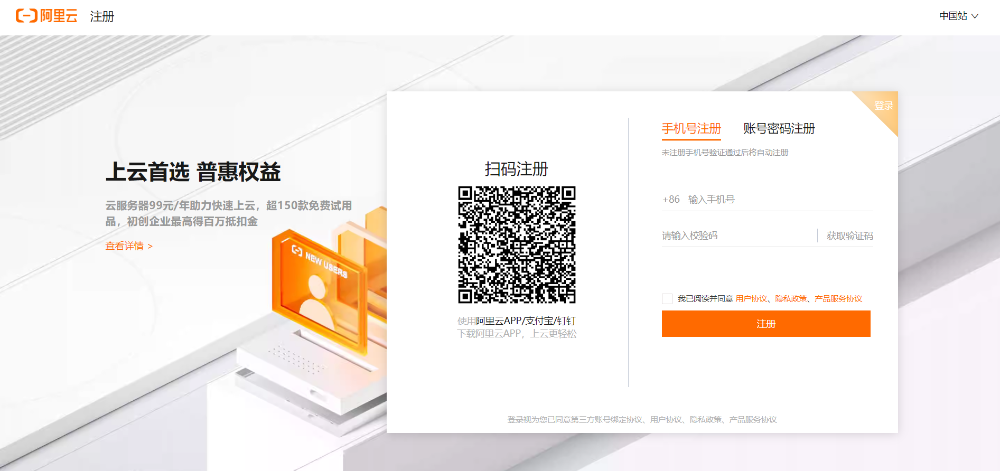

<strong>2). 注册完账号之后，就可以登录阿里云</strong>

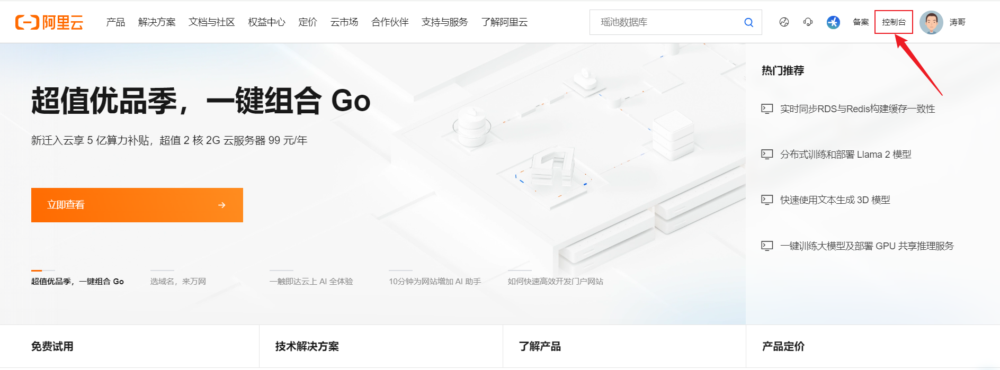


##### 3.3.1.3 开通OSS云服务

<strong>1). 通过控制台找到对象存储OSS服务</strong>

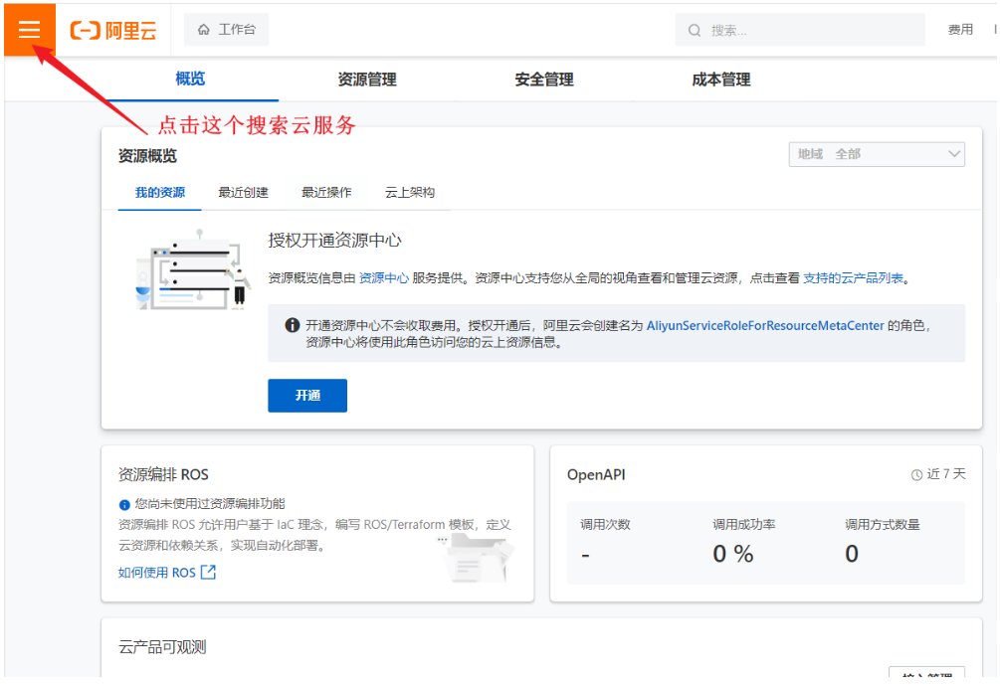

 选择要开通的服务

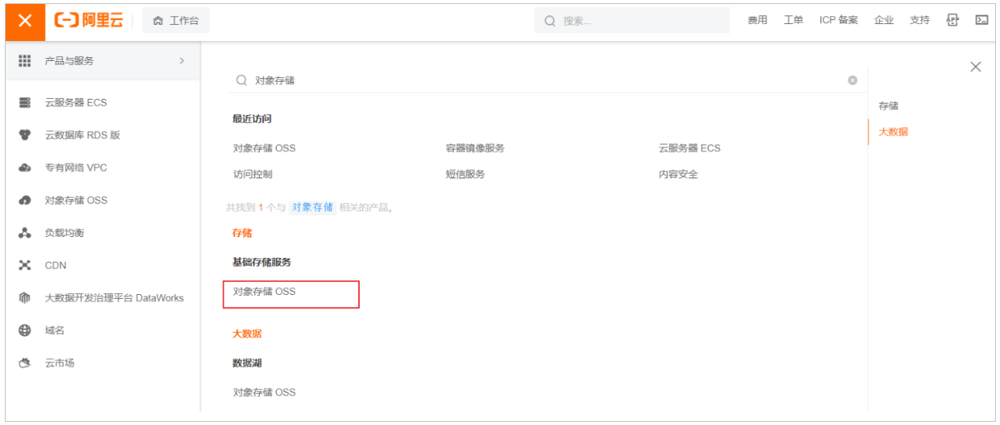

如果是第一次访问，还需要开通对象存储服务OSS 

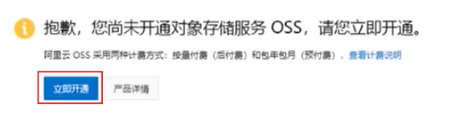

<strong>2). 开通OSS服务之后，就可以进入到阿里云对象存储的控制台</strong>

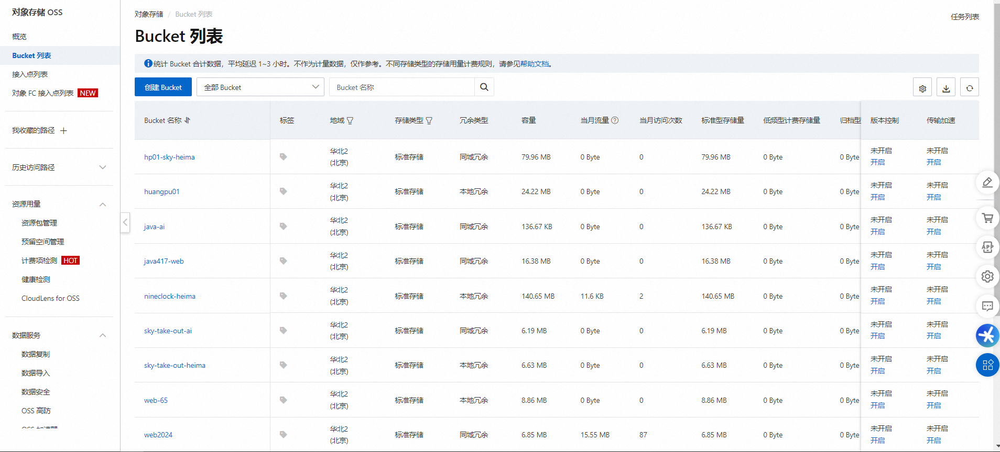

<strong>3). 点击左侧的 "Bucket列表"，创建一个Bucket</strong>

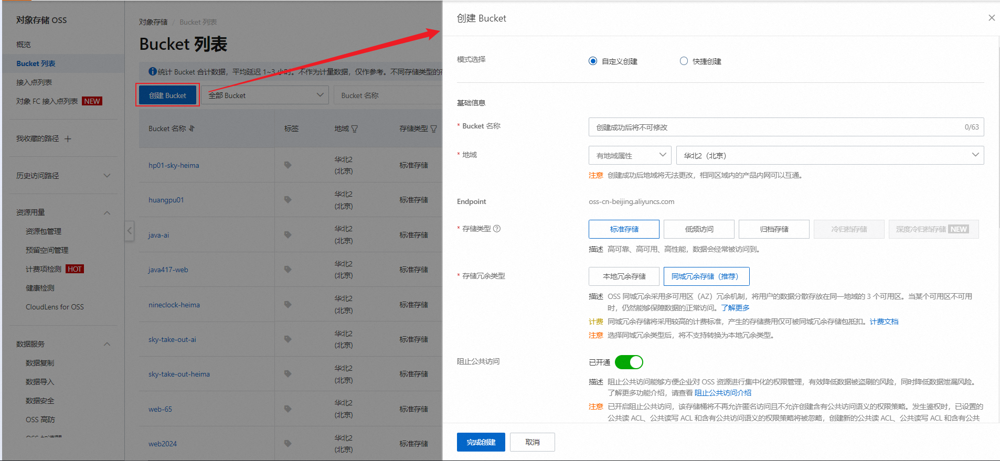

输入Bucket的相关信息.

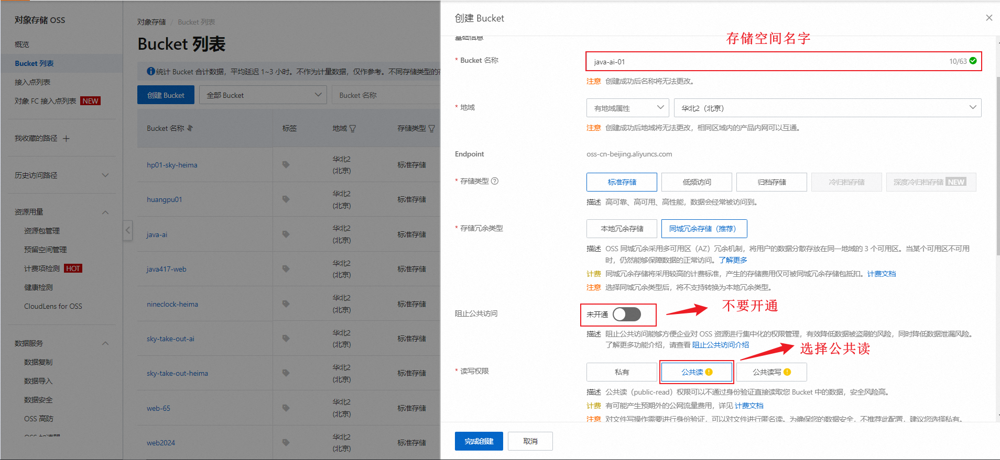

其他的信息，配置项使用默认的即可。


##### 3.3.1.4 配置AccessKey

<strong>1). 创建AccessKey</strong>

点击 "AccessKey管理"，进入到管理页面。

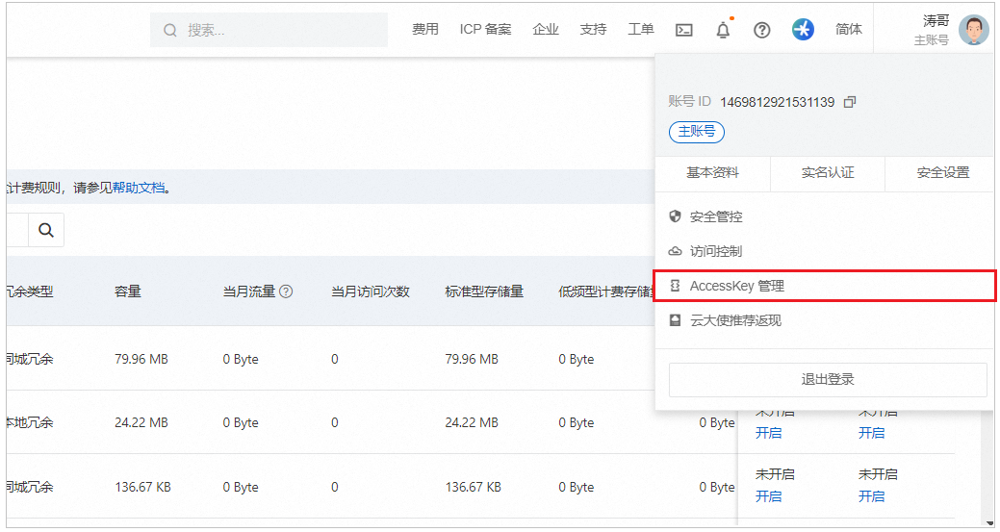

点击 "创建AccessKey"。

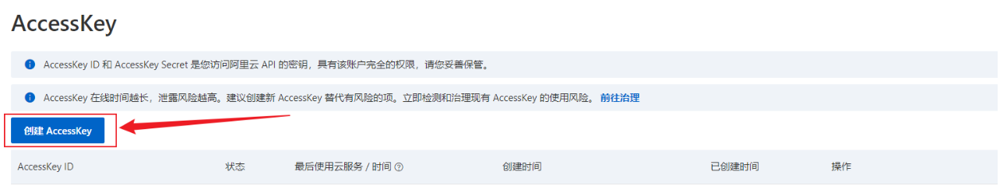

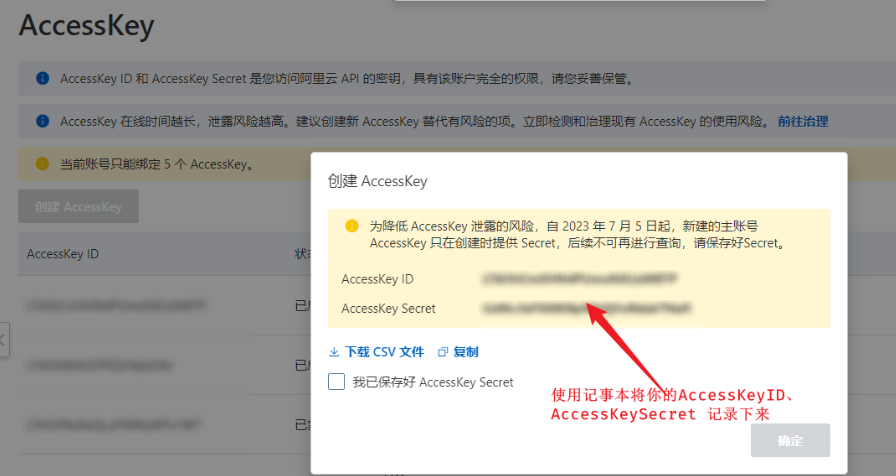

<strong>2).  配置AccessKey</strong>

以<strong>管理员身份</strong>打开CMD命令行，执行如下命令，配置系统的环境变量。

````sql
set OSS_ACCESS_KEY_ID=xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
set OSS_ACCESS_KEY_SECRET=xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
````

<strong>注意：将上述的ACCESS&#95;KEY&#95;ID  与 ACCESS&#95;KEY&#95;SECRET 的值</strong><strong>一定一定一定一定一定一定要替换成自己的 。</strong>

执行如下命令，让更改生效。

````shell
setx OSS_ACCESS_KEY_ID "%OSS_ACCESS_KEY_ID%"
setx OSS_ACCESS_KEY_SECRET "%OSS_ACCESS_KEY_SECRET%"
````

> **凭证提醒：**不要把真实 AccessKey 写进笔记、代码库、截图或聊天记录，也不要用 `echo` 输出密钥核对。使用最小权限的 RAM 身份或临时凭证；本地环境变量仅是课程练习方式。若凭证已经暴露，应立即停用并轮换。

执行如下命令，验证环境变量是否生效。

````shell
echo %OSS_ACCESS_KEY_ID%
echo %OSS_ACCESS_KEY_SECRET%
````


#### 3.3.2 入门

阿里云oss 对象存储服务的准备工作我们已经完成了，接下来我们就来完成第二步操作：参照官方所提供的sdk示例来编写入门程序。

首先我们需要来打开阿里云OSS的官方文档，在官方文档中找到 SDK 的示例代码：

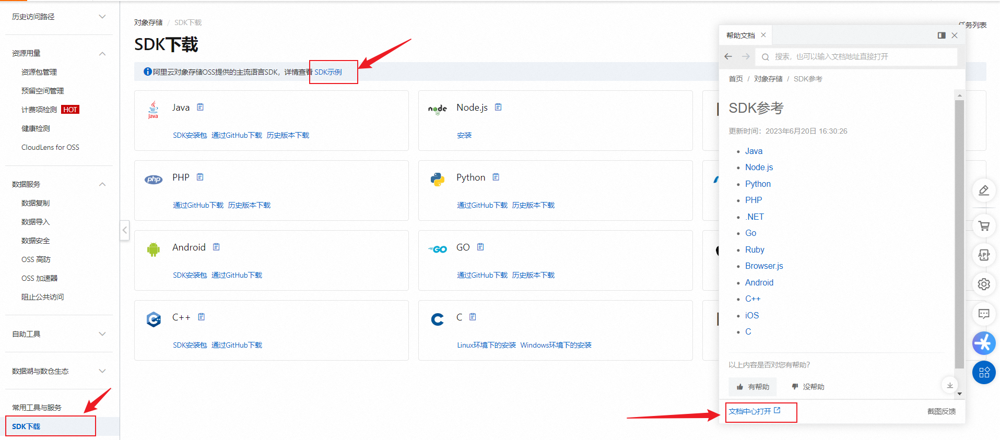

> 如果是在实际开发当中，我们是需要从前往后仔细的去阅读这一份文档的，但是由于现在是教学，我们就只挑重点的去看。有兴趣的同学大家下来也可以自己去看一下这份官方文档。

参照文档，引入依赖：

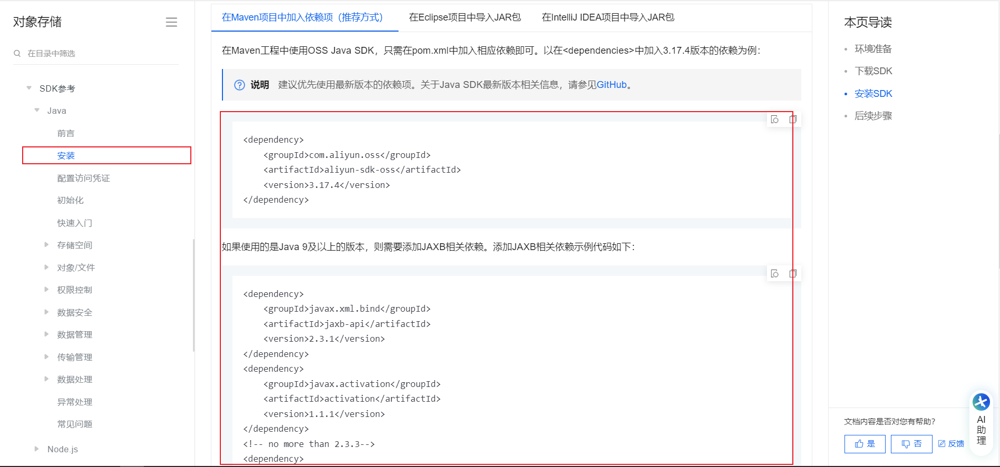

````xml
<!--阿里云OSS依赖-->
<dependency>
    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-sdk-oss</artifactId>
    <version>3.17.4</version>
</dependency>

<dependency>
    <groupId>javax.xml.bind</groupId>
    <artifactId>jaxb-api</artifactId>
    <version>2.3.1</version>
</dependency>
<dependency>
    <groupId>javax.activation</groupId>
    <artifactId>activation</artifactId>
    <version>1.1.1</version>
</dependency>
<!-- no more than 2.3.3-->
<dependency>
    <groupId>org.glassfish.jaxb</groupId>
    <artifactId>jaxb-runtime</artifactId>
    <version>2.3.3</version>
</dependency>
````

参照文档，编写入门程序：

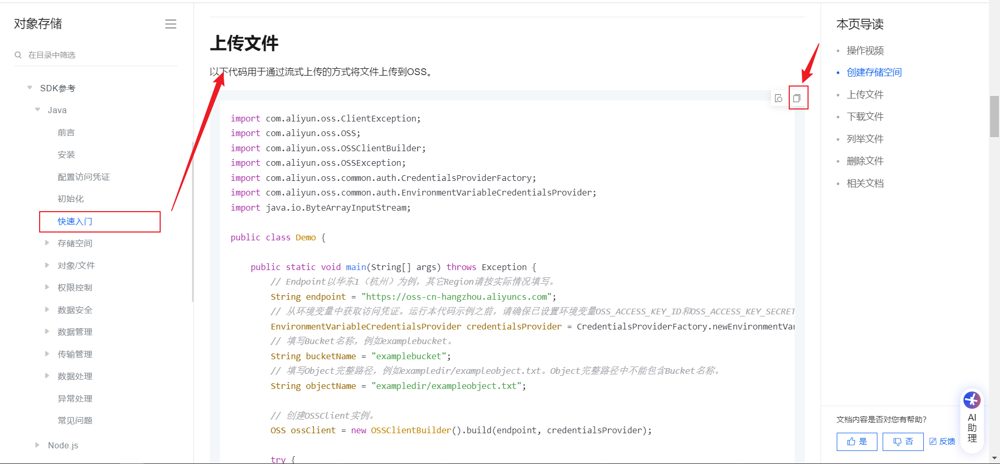

将官方提供的入门程序，复制过来，将里面的参数值改造成我们自己的即可。代码如下：

````java
package com.itheima;

import com.aliyun.oss.*;
import com.aliyun.oss.common.auth.CredentialsProviderFactory;
import com.aliyun.oss.common.auth.EnvironmentVariableCredentialsProvider;
import com.aliyun.oss.common.comm.SignVersion;

import java.io.ByteArrayInputStream;
import java.io.File;
import java.nio.file.Files;

public class Demo {

    public static void main(String[] args) throws Exception {
        // Endpoint以华东1（杭州）为例，其它Region请按实际情况填写。
        String endpoint = "https://oss-cn-beijing.aliyuncs.com";
        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();
        // 填写Bucket名称，例如examplebucket。
        String bucketName = "java-ai";
        // 填写Object完整路径，例如exampledir/exampleobject.txt。Object完整路径中不能包含Bucket名称。
        String objectName = "001.jpg";
        // 填写Bucket所在地域。以华东1（杭州）为例，Region填写为cn-hangzhou。
        String region = "cn-beijing";

        // 创建OSSClient实例。
        ClientBuilderConfiguration clientBuilderConfiguration = new ClientBuilderConfiguration();
        clientBuilderConfiguration.setSignatureVersion(SignVersion.V4);
        OSS ossClient = OSSClientBuilder.create()
            .endpoint(endpoint)
            .credentialsProvider(credentialsProvider)
            .clientConfiguration(clientBuilderConfiguration)
            .region(region)
            .build();

        try {
            File file = new File("C:\\Users\\deng\\Pictures\\1.jpg");
            byte[] content = Files.readAllBytes(file.toPath());

            ossClient.putObject(bucketName, objectName, new ByteArrayInputStream(content));
        } catch (OSSException oe) {
            System.out.println("Caught an OSSException, which means your request made it to OSS, "
                    + "but was rejected with an error response for some reason.");
            System.out.println("Error Message:" + oe.getErrorMessage());
            System.out.println("Error Code:" + oe.getErrorCode());
            System.out.println("Request ID:" + oe.getRequestId());
            System.out.println("Host ID:" + oe.getHostId());
        } catch (ClientException ce) {
            System.out.println("Caught an ClientException, which means the client encountered "
                    + "a serious internal problem while trying to communicate with OSS, "
                    + "such as not being able to access the network.");
            System.out.println("Error Message:" + ce.getMessage());
        } finally {
            if (ossClient != null) {
                ossClient.shutdown();
            }
        }
    }
}
````

切记，大家需要将上面的 <code>endpoint</code> ，<code>bucketName</code>，<code>objectName</code>，<code>file</code> 都需要改成自己的。

> 在以上代码中，需要替换的内容为：
> 
> - endpoint：阿里云OSS中的bucket对应的域名
> - bucketName：Bucket名称
> - objectName：对象名称，在Bucket中存储的对象的名称
> - region：bucket所属区域

运行以上程序后，会把本地的文件上传到阿里云OSS服务器上。


#### 3.3.3 集成


##### 3.3.3.1  介绍

阿里云oss对象存储服务的准备工作以及入门程序我们都已经完成了，接下来我们就需要在案例当中集成oss对象存储服务，来存储和管理案例中上传的图片。

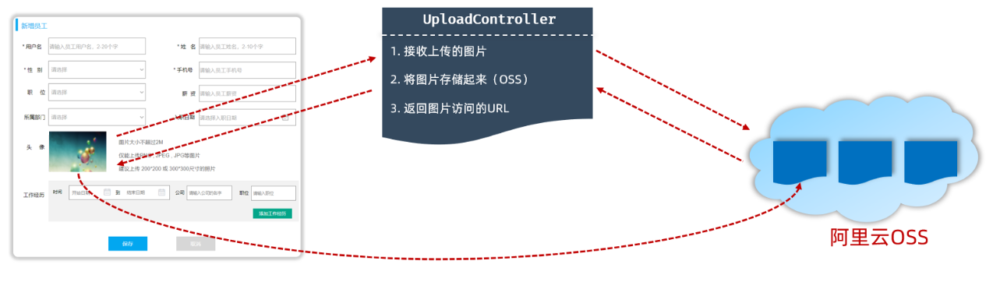

> 在新增员工的时候，上传员工的图像，而之所以需要上传员工的图像，是因为将来我们需要在系统页面当中访问并展示员工的图像。而要想完成这个操作，需要做两件事：
> 
> 1. 需要上传员工的图像，并把图像保存起来（存储到阿里云OSS）
> 2. 访问员工图像（通过图像在阿里云OSS的存储地址访问图像）
> 
>     - OSS中的每一个文件都会分配一个访问的url，通过这个url就可以访问到存储在阿里云上的图片。所以需要把url返回给前端，这样前端就可以通过url获取到图像。

我们参照接口文档来开发文件上传功能：

<strong>基本信息</strong>

- 请求路径：/upload<br>请求方式：POST<br>接口描述：上传图片接口

<strong>请求参数</strong>

- 参数格式：multipart/form-data
- 参数说明：

| 参数名称 | 参数类型 | 是否必须 | 示例 | 备注 |
| --- | --- | --- | --- | --- |
| image | file | 是 |  |  |

> **接口核对：**讲义上传表格把字段名写为 `image`，示例 Controller 使用 `MultipartFile file`，两者不一致时必须用 `@RequestParam("image") MultipartFile file`，或统一双方字段名。

<strong>响应数据</strong>

- 参数格式：application/json
- 参数说明：

| 参数名 | 类型 | 是否必须 | 备注 |
| --- | --- | --- | --- |
| code | number | 必须 | 响应码，1 代表成功，0 代表失败 |
| msg | string | 非必须 | 提示信息 |
| data | object | 非必须 | 返回的数据，上传图片的访问路径 |

> **返回值：**`data` 是图片访问地址，不代表地址必然公开可访问；应按 OSS Bucket 权限决定公开 URL、签名 URL 或代理下载。

- 响应数据样例：

````json
{
    "code": 1,
    "msg": "success",
    "data": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2022-09-02-00-27-0400.jpg"
}
````


##### 3.3.3.2 实现

<strong>1). 引入阿里云OSS上传文件工具类（由官方的示例代码改造而来）</strong>

````java
package com.itheima.utils;

import com.aliyun.oss.*;
import com.aliyun.oss.common.auth.CredentialsProviderFactory;
import com.aliyun.oss.common.auth.EnvironmentVariableCredentialsProvider;
import com.aliyun.oss.common.comm.SignVersion;
import org.springframework.stereotype.Component;
import java.io.ByteArrayInputStream;
import java.time.LocalDate;
import java.time.format.DateTimeFormatter;
import java.util.UUID;

@Component
public class AliyunOSSOperator {

    private String endpoint = "https://oss-cn-beijing.aliyuncs.com";
    private String bucketName = "java-ai";
    private String region = "cn-beijing";

    public String upload(byte[] content, String originalFilename) throws Exception {
        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();

        // 填写Object完整路径，例如202406/1.png。Object完整路径中不能包含Bucket名称。
        //获取当前系统日期的字符串,格式为 yyyy/MM
        String dir = LocalDate.now().format(DateTimeFormatter.ofPattern("yyyy/MM"));
        //生成一个新的不重复的文件名
        String newFileName = UUID.randomUUID() + originalFilename.substring(originalFilename.lastIndexOf("."));
        String objectName = dir + "/" + newFileName;

        // 创建OSSClient实例。
        ClientBuilderConfiguration clientBuilderConfiguration = new ClientBuilderConfiguration();
        clientBuilderConfiguration.setSignatureVersion(SignVersion.V4);
        OSS ossClient = OSSClientBuilder.create()
                .endpoint(endpoint)
                .credentialsProvider(credentialsProvider)
                .clientConfiguration(clientBuilderConfiguration)
                .region(region)
                .build();

        try {
            ossClient.putObject(bucketName, objectName, new ByteArrayInputStream(content));
        } finally {
            ossClient.shutdown();
        }

        return endpoint.split("//")[0] + "//" + bucketName + "." + endpoint.split("//")[1] + "/" + objectName;
    }

}
````

<strong>2). 修改UploadController代码</strong>

````java
package com.itheima.controller;

import com.itheima.pojo.Result;
import com.itheima.utils.AliyunOSSOperator;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RestController;
import org.springframework.web.multipart.MultipartFile;
import java.io.File;
import java.util.UUID;

@Slf4j
@RestController
public class UploadController {
    
    @Autowired
    private AliyunOSSOperator aliyunOSSOperator;

    @PostMapping("/upload")
    public Result upload(MultipartFile file) throws Exception {
        log.info("上传文件：{}", file);
        if (!file.isEmpty()) {
            // 生成唯一文件名
            String originalFilename = file.getOriginalFilename();
            String extName = originalFilename.substring(originalFilename.lastIndexOf("."));
            String uniqueFileName = UUID.randomUUID().toString().replace("-", "") + extName;
            // 上传文件
            String url = aliyunOSSOperator.upload(file.getBytes(), uniqueFileName);
            return Result.success(url);
        }
        return Result.error("上传失败");
    }

}
````

> **文件名勘误：**上传 Controller 生成一次 UUID，`AliyunOSSOperator.upload` 又生成一次，前一次没有实际防重作用。应由一个层负责生成对象键；先校验空文件、大小、类型，再用受控扩展名生成键。不要直接信任 `originalFilename`，也不要把用户传入的 OSS URL 当作已验证头像地址。

使用 Apifox 测试：

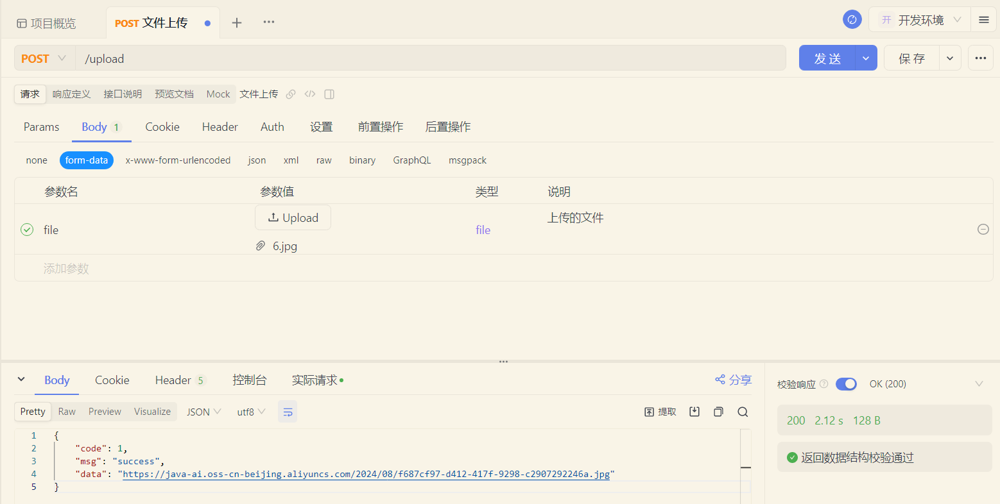

接口测试通过之后，我们就可以进行前后端联调了。


### 3.4 功能优化

员工管理的新增功能我们已开发完成，但在我们所开发的程序中还一些小问题，下面我们就来分析一下当前案例中存在的问题以及如何优化解决。

在刚才我们制作的AliyunOSS操作的工具类中，我们直接将 endpoint、bucketName参数直接在java文件中写死了。如下所示：

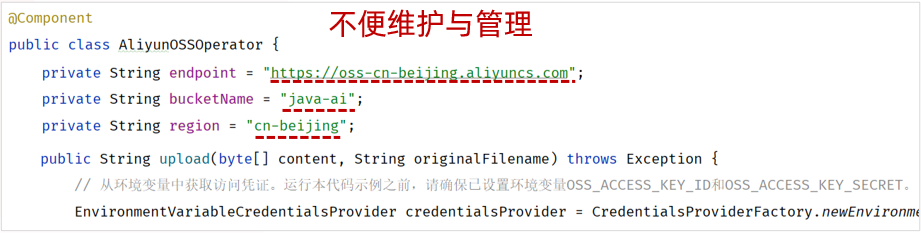

如果后续，项目要部署到测试环境、上生产环境，我们需要来修改这两个参数。 而如果开发一个大型项目，所有用到的技术涉及到的这些个参数全部写死在java代码中，是非常不便于维护和管理的。 

那么对于这些容易变动的参数，我们可以将其配置在配置文件中，然后通过 <code>@Value</code> 注解来注解外部配置的属性。如下所示：

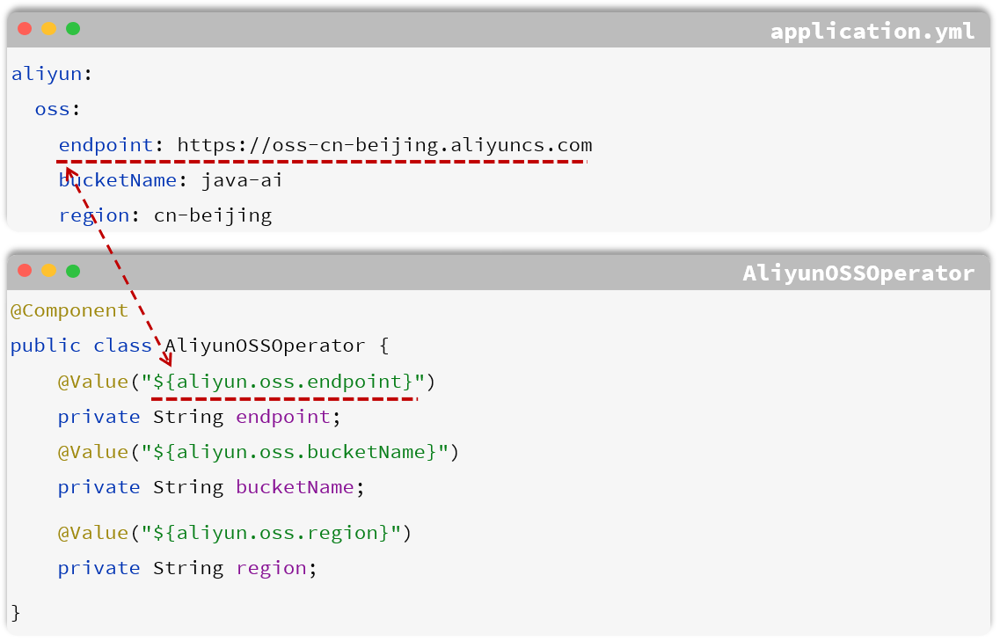

具体实现代码如下：

<strong>1). application.yml</strong>

````yaml
#阿里云OSS
aliyun:
  oss:
    endpoint: https://oss-cn-beijing.aliyuncs.com
    bucketName: java-ai
    region: cn-beijing
````

<strong>2). AliyunOSSOperator</strong>

````java
package com.itheima.utils;

import com.aliyun.oss.*;
import com.aliyun.oss.common.auth.CredentialsProviderFactory;
import com.aliyun.oss.common.auth.EnvironmentVariableCredentialsProvider;
import com.aliyun.oss.common.comm.SignVersion;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.beans.factory.annotation.Value;
import org.springframework.stereotype.Component;
import java.io.ByteArrayInputStream;
import java.time.LocalDate;
import java.time.format.DateTimeFormatter;
import java.util.UUID;

@Component
public class AliyunOSSOperator {

    //方式一: 通过@Value注解一个属性一个属性的注入
    @Value("${aliyun.oss.endpoint}")
    private String endpoint;
    
    @Value("${aliyun.oss.bucketName}")
    private String bucketName;
    
    @Value("${aliyun.oss.region}")
    private String region;

    public String upload(byte[] content, String originalFilename) throws Exception {
        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();

        // 填写Object完整路径，例如2024/06/1.png。Object完整路径中不能包含Bucket名称。
        //获取当前系统日期的字符串,格式为 yyyy/MM
        String dir = LocalDate.now().format(DateTimeFormatter.ofPattern("yyyy/MM"));
        //生成一个新的不重复的文件名
        String newFileName = UUID.randomUUID() + originalFilename.substring(originalFilename.lastIndexOf("."));
        String objectName = dir + "/" + newFileName;

        // 创建OSSClient实例。
        ClientBuilderConfiguration clientBuilderConfiguration = new ClientBuilderConfiguration();
        clientBuilderConfiguration.setSignatureVersion(SignVersion.V4);
        OSS ossClient = OSSClientBuilder.create()
                .endpoint(endpoint)
                .credentialsProvider(credentialsProvider)
                .clientConfiguration(clientBuilderConfiguration)
                .region(region)
                .build();

        try {
            ossClient.putObject(bucketName, objectName, new ByteArrayInputStream(content));
        } finally {
            ossClient.shutdown();
        }

        return endpoint.split("//")[0] + "//" + bucketName + "." + endpoint.split("//")[1] + "/" + objectName;
    }

}
````

> **存储边界：**OSS 上传不受数据库 `@Transactional` 回滚控制。若对象已上传、员工写库失败，会留下孤儿对象；可在失败路径做清理或定期扫描，并权衡删除失败后的重试。返回的对象 URL 也不一定可公开访问，取决于 Bucket 访问策略；私有读场景应使用签名 URL 或受控代理。

如果只有一两个属性需要注入，而且不需要考虑复用性，使用<code>@Value</code>注解就可以了。

但是使用@Value注解注入配置文件的配置项，如果配置项多，注入繁琐，不便于维护管理 和 复用。如下所示:

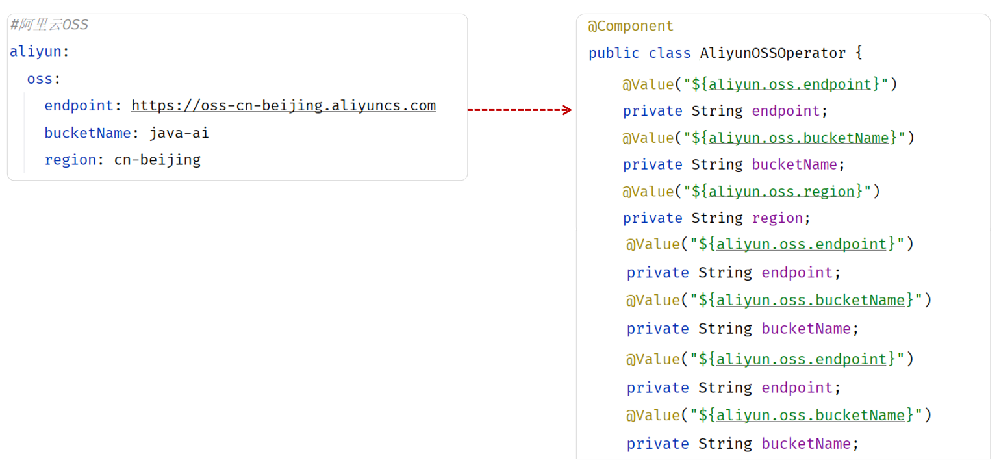

那么有没有一种方式可以简化这些配置参数的注入呢？答案是肯定有，在Spring中给我们提供了一种简化方式，可以直接将配置文件中配置项的值自动的注入到对象的属性中。

Spring提供的简化方式套路：

1). 需要创建一个实现类，且实体类中的属性名和配置文件当中key的名字必须要一致

     比如：配置文件当中叫endpoint，实体类当中的属性也得叫endpoint，另外实体类当中的属性还需要提供 getter / setter方法

2). 需要将实体类交给Spring的IOC容器管理，成为IOC容器当中的bean对象

3). 在实体类上添加<code>@ConfigurationProperties</code>注解，并通过perfect属性来指定配置参数项的前缀

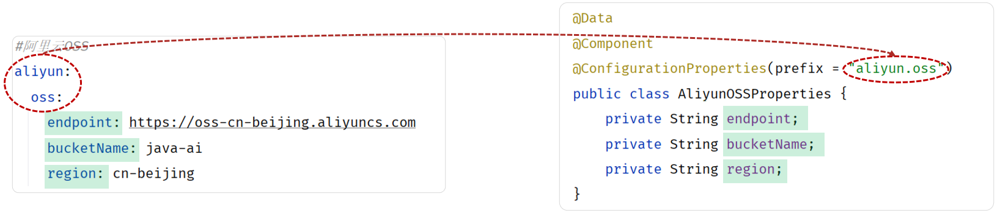

<strong>具体实现步骤:</strong>

1). 定义实体类AliyunOSSProperties ，并交给IOC容器管理

````java
package com.itheima.utils;

import lombok.Data;
import org.springframework.boot.context.properties.ConfigurationProperties;
import org.springframework.stereotype.Component;

@Data
@Component
@ConfigurationProperties(prefix = "aliyun.oss")
public class AliyunOSSProperties {
    private String endpoint;
    private String bucketName;
    private String region;
}
````

2). 修改AliyunOSSOperator

````java
package com.itheima.utils;

import com.aliyun.oss.*;
import com.aliyun.oss.common.auth.CredentialsProviderFactory;
import com.aliyun.oss.common.auth.EnvironmentVariableCredentialsProvider;
import com.aliyun.oss.common.comm.SignVersion;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.beans.factory.annotation.Value;
import org.springframework.stereotype.Component;
import java.io.ByteArrayInputStream;
import java.time.LocalDate;
import java.time.format.DateTimeFormatter;
import java.util.UUID;

@Component
public class AliyunOSSOperator {

    //方式一: 通过@Value注解一个属性一个属性的注入
    //@Value("${aliyun.oss.endpoint}")
    //private String endpoint;
    //@Value("${aliyun.oss.bucketName}")
    //private String bucketName;
    //@Value("${aliyun.oss.region}")
    //private String region;

    @Autowired
    private AliyunOSSProperties aliyunOSSProperties;

    public String upload(byte[] content, String originalFilename) throws Exception {
        String endpoint = aliyunOSSProperties.getEndpoint();
        String bucketName = aliyunOSSProperties.getBucketName();
        String region = aliyunOSSProperties.getRegion();

        // 从环境变量中获取访问凭证。运行本代码示例之前，请确保已设置环境变量OSS_ACCESS_KEY_ID和OSS_ACCESS_KEY_SECRET。
        EnvironmentVariableCredentialsProvider credentialsProvider = CredentialsProviderFactory.newEnvironmentVariableCredentialsProvider();

        // 填写Object完整路径，例如2024/06/1.png。Object完整路径中不能包含Bucket名称。
        //获取当前系统日期的字符串,格式为 yyyy/MM
        String dir = LocalDate.now().format(DateTimeFormatter.ofPattern("yyyy/MM"));
        //生成一个新的不重复的文件名
        String newFileName = UUID.randomUUID() + originalFilename.substring(originalFilename.lastIndexOf("."));
        String objectName = dir + "/" + newFileName;

        // 创建OSSClient实例。
        ClientBuilderConfiguration clientBuilderConfiguration = new ClientBuilderConfiguration();
        clientBuilderConfiguration.setSignatureVersion(SignVersion.V4);
        OSS ossClient = OSSClientBuilder.create()
                .endpoint(endpoint)
                .credentialsProvider(credentialsProvider)
                .clientConfiguration(clientBuilderConfiguration)
                .region(region)
                .build();

        try {
            ossClient.putObject(bucketName, objectName, new ByteArrayInputStream(content));
        } finally {
            ossClient.shutdown();
        }

        return endpoint.split("//")[0] + "//" + bucketName + "." + endpoint.split("//")[1] + "/" + objectName;
    }

}
````


## 4 补充：一次新增员工请求的完整链路

第 08 章的 `GET /emps` 只读列表。本章的 `POST /emps` 先在 `emp` 插入基本信息，利用 MyBatis 主键回填拿到 `emp.id`，再给每段 `EmpExpr` 设 `empId`，通过 `<foreach>` 批量写入 `emp_expr`。这两个写库步骤属于一个业务动作，应在 Service 的同一个事务中执行；工作经历为空时，只插入员工。

| 环节 | 本章知识点 | 核对项 |
| --- | --- | --- |
| 接口 | `@PostMapping`、`@RequestBody` | JSON 字段与实体属性对应；新增接口不返回密码 |
| 员工入库 | `@Options(useGeneratedKeys = true, keyProperty = "id")` | 数据库确实生成主键，插入后 `emp.id` 非空 |
| 工作经历 | `@Param("exprList")` 与 XML `<foreach>` | `collection` 名一致；空列表不调用批量 SQL |
| 事务 | `@Transactional(rollbackFor = Exception.class)` | 两次写库要么都提交，要么都回滚 |
| 上传 | `multipart/form-data`、`MultipartFile`、OSS | 上传接口先得到受控地址，再作为员工头像字段提交 |

**注意两个边界：**`@Transactional` 默认只回滚运行时异常与 `Error`；受检异常要用 `rollbackFor` 指定。它只管理数据库连接上的事务，不能回滚已经上传到 OSS 的对象。课程中的同名类是逐步改造的阶段性代码，只应保留最终实现；示例 `int i = 1 / 0` 必须在完成回滚实验后删除。


## 5 补充：基于第 08 章项目跟练

继续使用第 08 章的 Spring Boot/MyBatis 工程、`emp` 与 `dept` 表；本章还需要 `emp_expr` 表。以下片段是要加入**对应工程文件**的关键部分，不在 Notebook 的 Python 内核执行。包名、字段类型应以自己的项目为准。生产接口建议把输入与数据库实体分开，并补充 Bean Validation、账号初始化和权限控制。

### 5.1 Service 保证两表一致

`EmpMapper.insert` 使用讲义的主键回填配置，`EmpExprMapper` 的集合参数显式命名。Service 的公开方法由 Controller 经 Spring Bean 调用，不通过同类自调用绕过事务代理。

```java
@Mapper
public interface EmpExprMapper {
    void insertBatch(@Param("exprList") List<EmpExpr> exprList);
}

@Service
public class EmpServiceImpl implements EmpService {
    private final EmpMapper empMapper;
    private final EmpExprMapper empExprMapper;

    public EmpServiceImpl(EmpMapper empMapper, EmpExprMapper empExprMapper) {
        this.empMapper = empMapper;
        this.empExprMapper = empExprMapper;
    }

    @Override
    @Transactional(rollbackFor = Exception.class)
    public void save(Emp emp) {
        LocalDateTime now = LocalDateTime.now();
        emp.setCreateTime(now);
        emp.setUpdateTime(now);
        empMapper.insert(emp); // @Options 回填 emp.id

        List<EmpExpr> exprList = emp.getExprList();
        if (exprList != null && !exprList.isEmpty()) {
            exprList.forEach(expr -> expr.setEmpId(emp.getId()));
            empExprMapper.insertBatch(exprList);
        }
    }
}
```

`EmpExprMapper.xml` 的 `namespace` 和 `insert id` 必须对应上述接口；参数值用 `#{...}` 绑定，不使用 `${...}` 拼接：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpExprMapper">
    <insert id="insertBatch">
        INSERT INTO emp_expr (emp_id, begin, end, company, job) VALUES
        <foreach collection="exprList" item="expr" separator=",">
            (#{expr.empId}, #{expr.begin}, #{expr.end}, #{expr.company}, #{expr.job})
        </foreach>
    </insert>
</mapper>
```

`EmpService` 接口仍需声明 `void save(Emp emp)`；`EmpMapper.insert` 保留讲义的 `@Options(useGeneratedKeys = true, keyProperty = "id")`。这些示例的 `Emp` 仍沿用课程结构，为了理解链路而保留；实际接口不应让客户端直接设置 `id`、创建时间、密码或任意部门之外的内部字段。


### 5.2 验证事务，而不留下故障代码

先用测试库创建一个唯一用户名和两段工作经历，调用 `POST /emps`。确认 `emp` 只有一行，`emp_expr` 恰好两行，两个 `emp_id` 都等于回填主键；再用空 `exprList` 测试只写员工。随后用**临时测试代码**在第二次插入前抛出运行时异常，确认两张表均没有新增记录。受检异常场景要配 `rollbackFor = Exception.class`，且异常必须传出代理方法。测试结束后移除故障注入。

`REQUIRED` 是默认传播行为，内层 Service 加入外层事务；`REQUIRES_NEW` 会挂起外层、独立提交内层日志事务。课程的 `emp_log` 案例说明外层失败时日志仍能留下，但不能直接把 `emp.toString()` 写入日志：其中可能有密码和个人信息。记录员工 ID、动作、状态和脱敏错误摘要即可。若日志业务有强可靠要求，还应考虑日志事务自身失败、重试与跨系统一致性。

| 场景 | 预期结果 |
| --- | --- |
| 员工 + 两段经历成功 | `emp` 1 行、`emp_expr` 2 行 |
| 员工 + 空经历成功 | `emp` 1 行、`emp_expr` 0 行 |
| 经历插入失败 | 两表新增均回滚 |
| 外层失败、日志用 `REQUIRED` | 员工与日志一起回滚 |
| 外层失败、日志用 `REQUIRES_NEW` | 员工回滚，内层已提交的日志保留 |


## 6 补充：文件上传的实际检查顺序

讲义先演示本地磁盘，再演示 OSS。表单需 `POST`、`multipart/form-data` 和文件域。讲义的上传接口表把文件字段写作 `image`，所以 Controller 应使用 `@RequestParam("image") MultipartFile file`；若前端发送的是 `file`，就把两边统一为 `file`。不一致会导致绑定失败。`application.yml` 的顶层键是半角 `spring:`，讲义全角冒号示例不能直接复制。

1. 接收时拒绝空文件，并按头像场景限制大小。单文件上限、请求总上限、网关限制要一致。
2. 校验允许的图片格式和文件实际内容；`getOriginalFilename()`、`getContentType()` 均来自客户端，不能单独作为可信依据。
3. 由服务端生成对象键与受控扩展名，不把用户文件名拼入服务器路径或 OSS 键；不要在日志中打印文件内容、凭证或完整请求对象。
4. 用最小权限凭证上传。`endpoint`、Bucket、Region 要匹配；SDK 返回成功后，按 Bucket 公有读或私有读策略提供访问地址。
5. 保存员工失败时，考虑清理已经上传的对象，或记录待清理键由后台任务补偿。数据库回滚不能撤销 OSS 上传。

本章的 OSS 代码从环境变量读取 `OSS_ACCESS_KEY_ID`、`OSS_ACCESS_KEY_SECRET`。不要把真实值写入 `application.yml` 或 Notebook；不要通过回显密钥来检查配置。使用阿里云 RAM 的最小权限身份，长期部署优先使用适合环境的临时凭证方案。

跟练时按 **空文件、非图片、超过大小、同名文件、正常图片、私有 Bucket 访问** 六种情况分别测试。没有阿里云账号也可以先完成本地上传和事务实验；OSS 环节需要自己的 Bucket 与凭证，本次笔记整理没有执行真实上传。


补充核对资料：[Spring 声明式事务](https://docs.spring.io/spring-framework/reference/data-access/transaction/declarative/annotations.html)、[Spring 事务回滚规则](https://docs.spring.io/spring-framework/reference/data-access/transaction/declarative/rolling-back.html)、[MyBatis XML 映射](https://mybatis.org/mybatis-3/sqlmap-xml.html)、[Spring 文件上传](https://docs.spring.io/spring-framework/reference/web/webmvc/mvc-controller/ann-methods/multipart-forms.html)、[阿里云 OSS Java SDK](https://help.aliyun.com/zh/oss/developer-reference/java)。
